# 로보택시 기본 모델: 작은 사례 구현 검증
도시 3개·동일 확률 시나리오 10개. 임의 설정한 **합성 입력값**을 사용합니다.

1. 설정한 기본값으로 MILP solver으로 계산한 최적화 결과와 독립 전수계산 일치여부 확인

2. 설정한 기본값으로 엣지 케이스 확인

3. 민감도 분석

※ 목적함수는 초기 진입비 + 연간 차량비 + 시나리오 평균 유휴 페널티·미충족 손실입니다. y와 q는 시나리오 공통이고 O와 U는 시나리오별 변수입니다.

솔버: [SciPy milp / HiGHS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html)

In [ ]:
# Colab 기본 환경에 필요한 패키지가 없을 때만 설치합니다.
try:
    from scipy.optimize import milp
    import pandas
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy", "pandas", "scipy>=1.9"])

# 1. 설정한 기본값으로 solver 최적화 값과 독립 전수계산 일치여부 확인

## 1-1. 준비

In [ ]:
"""도시 3개·시나리오 10개의 합성 구현 검증.
"""
from itertools import product
from fractions import Fraction
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint

def show(title, table):
    print('\n' + title)
    try:
        from IPython import get_ipython
        from IPython.display import display
        if get_ipython() is not None:
            display(table)
            return
    except ImportError:
        pass
    print(table.to_string(index=False))

## 1-2. 도시별 입력값과 입력표

In [ ]:
# 순서: A, B, C. 비용은 초기 1회 F, 차량당 연간 K, 통행당 c+/c-이다.
cities = ['A', 'B', 'C']
M = np.array([80., 100., 120.])
kappa = np.array([10., 10., 10.])
qbar = np.array([2, 2, 2])
F = np.array([20., 20., 20.])
K = np.array([5., 5., 5.])
c_plus = np.array([0., 0., 0.])
c_minus = np.array([10., 10., 10.])
Q = 4

input_table = pd.DataFrame({
    '입력': ['M_c', 'kappa_c', 'qbar_c', 'F_c', 'K_c', 'c_plus', 'c_minus'],
    '단위': ['건/년', '건/대·년', '대', 'USD/진입 1회', 'USD/대·년',
             'USD/미사용 용량 1건', 'USD/미충족 통행 1건'],
    **{name: [a[i] for a in [M, kappa, qbar, F, K, c_plus, c_minus]]
       for i, name in enumerate(cities)},})
show('입력표', input_table)


입력표


,입력,단위,A,B,C
0,M_c,건/년,80.0,100.0,120.0
1,kappa_c,건/대·년,10.0,10.0,10.0
2,qbar_c,대,2.0,2.0,2.0
3,F_c,USD/진입 1회,20.0,20.0,20.0
4,K_c,USD/대·년,5.0,5.0,5.0
5,c_plus,USD/미사용 용량 1건,0.0,0.0,0.0
6,c_minus,USD/미충족 통행 1건,10.0,10.0,10.0


## 1-3. 공통 설정과 10개 공동 시나리오

In [ ]:
# 각 행이 하나의 공동 시나리오이다. 4^3개 조합으로 확장하지 않는다.
p = np.array([
    [.05, .05, .05], [.20, .20, .20], [.50, .50, .50], [.80, .80, .80],
    [.05, .20, .50], [.20, .50, .05], [.50, .05, .20],
    [.20, .50, .80], [.50, .80, .20], [.80, .20, .50]])
S, C = p.shape
probability = np.full(S, 1 / S)  # 시나리오 확률과 선택확률 p는 다르다.
D = p * M[None, :]              # 시나리오가 바뀌어도 도시별 M은 고정된다.

common_table = pd.DataFrame([
    ('후보 도시', ', '.join(cities)), ('시나리오 수', str(S)),
    ('시나리오 확률', f'각각 1/{S}'), ('총차량 Q', str(Q)),
    ('Q 후속 비교 수준', '0·4·8대 (이번에는 미실행)'),
    ('선택확률 수준', ', '.join(map(str, np.unique(p)))),
    ('평가기간', '진입·배치를 한 번 결정하고 1년 운영'),
    ('공통 의사결정', '모든 시나리오에 동일한 y_c, q_c'),
    ('시나리오별 변수', 'O_c^s, U_c^s'),
    ('실행 범위', '기본 사례 MILP + 독립 전수계산 검증')], columns=['항목', '설정'])
show('공통 설정표', common_table)
scenario_table = pd.DataFrame({'시나리오': np.arange(1, S + 1), '발생 확률': probability})
for i, name in enumerate(cities):
    scenario_table[f'p_{name}'] = p[:, i]
for i, name in enumerate(cities):
    scenario_table[f'D_{name} (건/년)'] = D[:, i]
show('선택확률과 수요 시나리오표', scenario_table)

# 입력 오류는 계산 전에 중단한다. 수요를 임의로 정수 반올림하지 않는다.
assert C == len(cities) and np.isfinite(p).all() and ((0 <= p) & (p <= 1)).all()
assert isinstance(Q, (int, np.integer)) and Q >= 0
assert np.isclose(probability.sum(), 1)
for a in [M, kappa, qbar, F, K, c_plus, c_minus]:
    assert a.shape == (C,) and np.isfinite(a).all() and (a >= 0).all()
assert np.equal(qbar, np.floor(qbar)).all()
qbar = qbar.astype(int)


공통 설정표


,항목,설정
0,후보 도시,"A, B, C"
1,시나리오 수,10
2,시나리오 확률,각각 1/10
3,총차량 Q,4
4,Q 후속 비교 수준,0·4·8대 (이번에는 미실행)
5,선택확률 수준,"0.05, 0.2, 0.5, 0.8"
6,평가기간,진입·배치를 한 번 결정하고 1년 운영
7,공통 의사결정,"모든 시나리오에 동일한 y_c, q_c"
8,시나리오별 변수,"O_c^s, U_c^s"
9,실행 범위,기본 사례 MILP + 독립 전수계산 검증



선택확률과 수요 시나리오표


,시나리오,발생 확률,p_A,p_B,p_C,D_A (건/년),D_B (건/년),D_C (건/년)
0,1,0.1,0.05,0.05,0.05,4.0,5.0,6.0
1,2,0.1,0.20,0.20,0.20,16.0,20.0,24.0
2,3,0.1,0.50,0.50,0.50,40.0,50.0,60.0
3,4,0.1,0.80,0.80,0.80,64.0,80.0,96.0
4,5,0.1,0.05,0.20,0.50,4.0,20.0,60.0
5,6,0.1,0.20,0.50,0.05,16.0,50.0,6.0
6,7,0.1,0.50,0.05,0.20,40.0,5.0,24.0
7,8,0.1,0.20,0.50,0.80,16.0,50.0,96.0
8,9,0.1,0.50,0.80,0.20,40.0,80.0,24.0
9,10,0.1,0.80,0.20,0.50,64.0,20.0,60.0


## 1-4. 목적함수와 제약식 구현

In [ ]:
# x = [y(도시), q(도시), O(시나리오×도시), U(시나리오×도시)]
iy = np.arange(C)
iq = np.arange(C, 2 * C)
iO = np.arange(2 * C, 2 * C + S * C).reshape(S, C)
iU = np.arange(2 * C + S * C, 2 * C + 2 * S * C).reshape(S, C)
nvars = 2 * C + 2 * S * C
objective = np.zeros(nvars)
objective[iy], objective[iq] = F, K
objective[iO] = probability[:, None] * c_plus
objective[iU] = probability[:, None] * c_minus

# y는 0 또는 1의 값을 가지는 정수(binary variable), q는 0 이상의 정수(비음 정수), O와 U는 0 이상의 연속 변수(비음 연속 변수)
lower = np.zeros(nvars)
upper = np.full(nvars, np.inf)
upper[iy], upper[iq] = 1, qbar
integrality = np.zeros(nvars, dtype=int)
integrality[iy] = integrality[iq] = 1

rows, lbs, ubs = [], [], []
def add_constraint(coefficients, lb, ub):
    row = np.zeros(nvars)
    for index, value in coefficients.items():
        row[index] = value
    rows.append(row)
    lbs.append(lb)
    ubs.append(ub)

for c in range(C):
    # q_c <= qbar_c * y_c : 미진입 도시에는 차량을 배치할 수 없다.
    add_constraint({iq[c]: 1, iy[c]: -qbar[c]}, -np.inf, 0)
add_constraint({idx: 1 for idx in iq}, -np.inf, Q)
for s in range(S):
    for c in range(C):
        # kappa*q - D = O - U  <=>  kappa*q - O + U = D
        add_constraint({iq[c]: kappa[c], iO[s, c]: -1, iU[s, c]: 1}, D[s, c], D[s, c])

result = milp(c=objective, integrality=integrality,
              bounds=Bounds(lower, upper),
              constraints=LinearConstraint(np.array(rows), np.array(lbs), np.array(ubs)),
              options={'mip_rel_gap': 0.0, 'time_limit': 60})
if result.status != 0:
    raise RuntimeError(f'최적해 확인 실패: status={result.status}, {result.message}')
x = result.x
y, q = np.rint(x[iy]).astype(int), np.rint(x[iq]).astype(int)
O_solver, U_solver = x[iO], x[iU]
capacity = kappa * q

## 1-5. 최적화 결과와 비용 분해

In [ ]:
show('도시별 최적 진입·배치', pd.DataFrame({
    '도시': cities, '진입 y': y, '차량 q': q,
    '연간 용량': capacity, '평균 수요': probability @ D,
    '기대 미사용 용량': probability @ O_solver,
    '기대 미충족 수요': probability @ U_solver}))

entry_cost = float(F @ y)
vehicle_cost = float(K @ q)
over_cost = float(np.sum(probability[:, None] * c_plus * O_solver))
under_cost = float(np.sum(probability[:, None] * c_minus * U_solver))
recalculated = entry_cost + vehicle_cost + over_cost + under_cost
show('목적함수 비용 분해 (USD)', pd.DataFrame({
    '항목': ['초기 진입비', '차량 고정비', '기대 유휴 페널티', '기대 미충족 손실', '합계'],
    'USD': [entry_cost, vehicle_cost, over_cost, under_cost, recalculated]}))
details = []
for s in range(S):
    for c, name in enumerate(cities):
        details.append([s + 1, name, D[s, c], capacity[c], O_solver[s, c], U_solver[s, c]])
show('시나리오별 수요·용량·손실 (건/년)', pd.DataFrame(
    details, columns=['시나리오', '도시', '수요 D', '용량', '미사용 O', '미충족 U']))



served = np.minimum(D, capacity[None, :])
unmet = np.maximum(D - capacity[None, :], 0)
unused = np.maximum(capacity[None, :] - D, 0)

scenario_summary = pd.DataFrame({
    "시나리오": np.arange(1, S + 1).astype(str),
    "전체 수요": D.sum(axis=1),
    "실제 처리": served.sum(axis=1),
    "미충족": unmet.sum(axis=1),
    "남는 용량": unused.sum(axis=1),
})

columns = ["전체 수요", "실제 처리", "미충족", "남는 용량"]

# 현재 모든 시나리오의 발생확률이 같으므로 합계 ÷ 시나리오 수로 평균 계산
totals = scenario_summary[columns].sum()
averages = totals / S

scenario_summary = pd.concat([
    scenario_summary,
    pd.DataFrame([
        {"시나리오": "합계", **totals.to_dict()},
        {"시나리오": f"평균: 합계 ÷ {S}", **averages.to_dict()},
    ]),
], ignore_index=True)

show(
    "시나리오별 전체 수요·실제 처리·미충족·남는 용량",
    scenario_summary.round(2),
)

print("※ 수치는 통행 건수이며, 달러 금액이 아닙니다.")
print("※ 합계는 서로 다른 시나리오의 계산용 합계이며, 한 해의 총수요가 아닙니다.")
print(
    f"평균 수요 {averages['전체 수요']:.1f}건"
    f" = 평균 처리 {averages['실제 처리']:.1f}건"
    f" + 평균 미충족 {averages['미충족']:.1f}건"
)
print(
    f"차량 용량 {capacity.sum():.1f}건"
    f" = 평균 처리 {averages['실제 처리']:.1f}건"
    f" + 평균 남는 용량 {averages['남는 용량']:.1f}건"
)


도시별 최적 진입·배치


,도시,진입 y,차량 q,연간 용량,평균 수요,기대 미사용 용량,기대 미충족 수요
0,A,0,0,0.0,30.4,0.0,30.4
1,B,1,2,20.0,38.0,3.0,21.0
2,C,1,2,20.0,45.6,2.8,28.4



목적함수 비용 분해 (USD)


,항목,USD
0,초기 진입비,40.0
1,차량 고정비,20.0
2,기대 유휴 페널티,0.0
3,기대 미충족 손실,798.0
4,합계,858.0



시나리오별 수요·용량·손실 (건/년)


,시나리오,도시,수요 D,용량,미사용 O,미충족 U
0,1,A,4.0,0.0,-0.0,4.0
1,1,B,5.0,20.0,15.0,0.0
2,1,C,6.0,20.0,14.0,-0.0
3,2,A,16.0,0.0,0.0,16.0
4,2,B,20.0,20.0,0.0,0.0
5,2,C,24.0,20.0,0.0,4.0
6,3,A,40.0,0.0,0.0,40.0
7,3,B,50.0,20.0,0.0,30.0
8,3,C,60.0,20.0,0.0,40.0
9,4,A,64.0,0.0,0.0,64.0



시나리오별 전체 수요·실제 처리·미충족·남는 용량


,시나리오,전체 수요,실제 처리,미충족,남는 용량
0,1,15.0,11.0,4.0,29.0
1,2,60.0,40.0,20.0,0.0
2,3,150.0,40.0,110.0,0.0
3,4,240.0,40.0,200.0,0.0
4,5,84.0,40.0,44.0,0.0
5,6,72.0,26.0,46.0,14.0
6,7,69.0,25.0,44.0,15.0
7,8,162.0,40.0,122.0,0.0
8,9,144.0,40.0,104.0,0.0
9,10,144.0,40.0,104.0,0.0


※ 수치는 통행 건수이며, 달러 금액이 아닙니다.
※ 합계는 서로 다른 시나리오의 계산용 합계이며, 한 해의 총수요가 아닙니다.
평균 수요 114.0건 = 평균 처리 34.2건 + 평균 미충족 79.8건
차량 용량 40.0건 = 평균 처리 34.2건 + 평균 남는 용량 5.8건


## 1-6. 종합 결과 분석
1. 세 도시에 진입하지 않은 이유? q[1,1,2] vs q[0,2,2] 비교.
- 추가 공헌이익은 8이지만 추가 진입비는 20입니다. 차량은 둘 다 4대이므로 차량비는 같습니다. 따라서 세 도시 배치의 목적함수는 870, 두 도시 배치보다 12 큽니다. 큰 시장을 무조건 선택한 것이 아니라 추가 처리량의 가치와 진입비를 함께 비교한 결과입니다.

2. 현재 조건에서는 시장규모가 큰 도시에 차량을 우선 배치하는 경향이 있다. q[1,1,2], vs q[1,2,1], vs q[2,1,1]

In [ ]:
from itertools import product

# 앞에서 정의한 변수 사용:
# D, kappa, F, K, c_plus, c_minus, probability, Q, qbar, show
#
# 현재 조건: 총 차량 최대 Q=4, 도시당 최대 qbar=[2,2,2]
# 차량을 한 대도 배치하지 않는 경우부터 모두 비교합니다.
# 진입비가 양수인 현재 조건에서는 차량이 없는 도시에
# 진입할 이유가 없으므로, 차량이 있는 도시만 진입한다고 계산합니다.
# 기존 최적화 결과 q, y는 변경하지 않습니다.

comparison_rows = []

# 도시별로 0대부터 최대 허용 대수까지 가능한 조합 생성
allocations = product(
    *[range(int(limit) + 1) for limit in qbar]
)

# 전체 기대 수요와 미진입 시 손실
mean_total_demand = float((probability @ D).sum())
no_entry_loss = float(c_minus @ (probability @ D))

for allocation in allocations:

    q_compare = np.array(allocation, dtype=int)

    # 전체 차량 한도를 초과하는 배치는 제외
    if q_compare.sum() > Q:
        continue

    y_compare = (q_compare > 0).astype(int)
    capacity_compare = kappa * q_compare

    # 1. 시나리오별·도시별 처리량 계산
    served_compare = np.minimum(D, capacity_compare[None, :])
    unmet_compare = np.maximum(D - capacity_compare[None, :], 0)
    unused_compare = np.maximum(capacity_compare[None, :] - D, 0)

    # 2. 시나리오 발생확률을 반영한 도시별 평균
    mean_served = probability @ served_compare
    mean_unmet = probability @ unmet_compare
    mean_unused = probability @ unused_compare

    total_served = float(mean_served.sum())
    total_unmet = float(mean_unmet.sum())
    total_unused = float(mean_unused.sum())
    total_capacity = float(capacity_compare.sum())

    # 처리율: 전체 기대 수요 중 처리한 비율
    service_rate = (
        100 * total_served / mean_total_demand
        if mean_total_demand > 0 else np.nan
    )

    # 활용률: 배치한 차량의 용량 중 사용한 비율
    utilization = (
        100 * total_served / total_capacity
        if total_capacity > 0 else np.nan
    )

    # 3. 비용과 서비스 공헌이익 계산
    entry = float(F @ y_compare)
    vehicle = float(K @ q_compare)
    idle_penalty = float(c_plus @ mean_unused)
    unmet_loss = float(c_minus @ mean_unmet)
    served_margin = float(c_minus @ mean_served)

    objective = entry + vehicle + idle_penalty + unmet_loss

    label = "[" + ",".join(map(str, allocation)) + "]"

    comparison_rows.append({
        "배치": label,
        "진입 도시 수": int(y_compare.sum()),
        "총 차량 수": int(q_compare.sum()),
        "A 평균 처리량": float(mean_served[0]),
        "B 평균 처리량": float(mean_served[1]),
        "C 평균 처리량": float(mean_served[2]),
        "전체 평균 처리량": total_served,
        "전체 평균 미충족": total_unmet,
        "전체 평균 남는 용량": total_unused,
        "처리율 (%)": service_rate,
        "활용률 (%)": utilization,
        "서비스 공헌이익": served_margin,
        "진입비": entry,
        "차량비": vehicle,
        "유휴 페널티": idle_penalty,
        "미충족 손실": unmet_loss,
        "목적함수": objective,
        "미진입 대비 개선": no_entry_loss - objective,
    })

comparison = pd.DataFrame(comparison_rows).set_index("배치")

# 4. 기준 배치 [0,2,2]와 비교
baseline_label = "[0,2,2]"

if baseline_label in comparison.index:
    baseline = comparison.loc[baseline_label].copy()

    comparison["기준 대비 처리량 증가"] = (
        comparison["전체 평균 처리량"] - baseline["전체 평균 처리량"]
    )
    comparison["기준 대비 공헌이익 증가"] = (
        comparison["서비스 공헌이익"] - baseline["서비스 공헌이익"]
    )
    comparison["기준 대비 진입비 증가"] = (
        comparison["진입비"] - baseline["진입비"]
    )
    comparison["기준 대비 차량비 증가"] = (
        comparison["차량비"] - baseline["차량비"]
    )
    comparison["기준 대비 유휴 페널티 증가"] = (
        comparison["유휴 페널티"] - baseline["유휴 페널티"]
    )
    comparison["기준 대비 목적함수 증가"] = (
        comparison["목적함수"] - baseline["목적함수"]
    )

# 5. 목적함수가 작은 순서대로 정렬
comparison = comparison.sort_values(
    ["목적함수", "총 차량 수"],
    kind="stable",
)

# 반올림 전 값으로 최적 배치 판별
best_objective = comparison["목적함수"].min()

comparison.insert(
    0,
    "최적 여부",
    np.where(
        np.isclose(
            comparison["목적함수"],
            best_objective,
            rtol=0,
            atol=1e-7,
        ),
        "최적",
        "",
    ),
)

# 6. 결과 출력
# NaN은 비율을 정의할 수 없는 경우이므로 '—'로 표시
def show_comparison(title, columns):
    table = comparison[columns].round(2).reset_index()
    show(title, table.fillna("—"))


show_comparison(
    "모든 배치의 처리량 비교 — 단위: 건",
    [
        "최적 여부",
        "총 차량 수",
        "진입 도시 수",
        "A 평균 처리량",
        "B 평균 처리량",
        "C 평균 처리량",
        "전체 평균 처리량",
        "전체 평균 미충족",
        "전체 평균 남는 용량",
    ],
)

show_comparison(
    "모든 배치의 처리율·활용률 비교",
    [
        "최적 여부",
        "총 차량 수",
        "처리율 (%)",
        "활용률 (%)",
    ],
)

show_comparison(
    "모든 배치의 공헌이익·비용 비교 — 단위: USD",
    [
        "최적 여부",
        "서비스 공헌이익",
        "진입비",
        "차량비",
        "유휴 페널티",
        "미충족 손실",
        "목적함수",
        "미진입 대비 개선",
    ],
)

if baseline_label in comparison.index:
    show_comparison(
        "[0,2,2] 대비 차이 — 처리량: 건 / 금액: USD",
        [
            "기준 대비 처리량 증가",
            "기준 대비 공헌이익 증가",
            "기준 대비 진입비 증가",
            "기준 대비 차량비 증가",
            "기준 대비 유휴 페널티 증가",
            "기준 대비 목적함수 증가",
        ],
    )

best_allocations = comparison.index[
    comparison["최적 여부"] == "최적"
].tolist()

print(f"비교한 배치 수: {len(comparison)}개")
print(f"최적 배치: {', '.join(best_allocations)}")
print(f"최소 목적함수: {best_objective:,.2f} USD")
print("※ 평균은 시나리오 발생확률을 반영한 값입니다.")
print("※ 목적함수 = 진입비 + 차량비 + 유휴 페널티 + 미충족 손실")
print("※ 미진입 대비 개선 = 미진입 시 손실 − 해당 배치의 목적함수")


모든 배치의 처리량 비교 — 단위: 건


,배치,최적 여부,총 차량 수,진입 도시 수,A 평균 처리량,B 평균 처리량,C 평균 처리량,전체 평균 처리량,전체 평균 미충족,전체 평균 남는 용량
0,"[0,2,2]",최적,4,2,0.0,17.0,17.2,34.2,79.8,5.8
1,"[1,1,2]",,4,3,8.8,9.0,17.2,35.0,79.0,5.0
2,"[1,2,1]",,4,3,8.8,17.0,9.2,35.0,79.0,5.0
3,"[2,0,2]",,4,2,15.6,0.0,17.2,32.8,81.2,7.2
4,"[2,2,0]",,4,2,15.6,17.0,0.0,32.6,81.4,7.4
5,"[2,1,1]",,4,3,15.6,9.0,9.2,33.8,80.2,6.2
6,"[0,1,2]",,3,2,0.0,9.0,17.2,26.2,87.8,3.8
7,"[0,2,1]",,3,2,0.0,17.0,9.2,26.2,87.8,3.8
8,"[1,0,2]",,3,2,8.8,0.0,17.2,26.0,88.0,4.0
9,"[1,2,0]",,3,2,8.8,17.0,0.0,25.8,88.2,4.2



모든 배치의 처리율·활용률 비교


,배치,최적 여부,총 차량 수,처리율 (%),활용률 (%)
0,"[0,2,2]",최적,4,30.00,85.5
1,"[1,1,2]",,4,30.70,87.5
2,"[1,2,1]",,4,30.70,87.5
3,"[2,0,2]",,4,28.77,82.0
4,"[2,2,0]",,4,28.60,81.5
5,"[2,1,1]",,4,29.65,84.5
6,"[0,1,2]",,3,22.98,87.33
7,"[0,2,1]",,3,22.98,87.33
8,"[1,0,2]",,3,22.81,86.67
9,"[1,2,0]",,3,22.63,86.0



모든 배치의 공헌이익·비용 비교 — 단위: USD


,배치,최적 여부,서비스 공헌이익,진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 대비 개선
0,"[0,2,2]",최적,342.0,40.0,20.0,0.0,798.0,858.0,282.0
1,"[1,1,2]",,350.0,60.0,20.0,0.0,790.0,870.0,270.0
2,"[1,2,1]",,350.0,60.0,20.0,0.0,790.0,870.0,270.0
3,"[2,0,2]",,328.0,40.0,20.0,0.0,812.0,872.0,268.0
4,"[2,2,0]",,326.0,40.0,20.0,0.0,814.0,874.0,266.0
5,"[2,1,1]",,338.0,60.0,20.0,0.0,802.0,882.0,258.0
6,"[0,1,2]",,262.0,40.0,15.0,0.0,878.0,933.0,207.0
7,"[0,2,1]",,262.0,40.0,15.0,0.0,878.0,933.0,207.0
8,"[1,0,2]",,260.0,40.0,15.0,0.0,880.0,935.0,205.0
9,"[1,2,0]",,258.0,40.0,15.0,0.0,882.0,937.0,203.0



[0,2,2] 대비 차이 — 처리량: 건 / 금액: USD


,배치,기준 대비 처리량 증가,기준 대비 공헌이익 증가,기준 대비 진입비 증가,기준 대비 차량비 증가,기준 대비 유휴 페널티 증가,기준 대비 목적함수 증가
0,"[0,2,2]",0.0,0.0,0.0,0.0,0.0,0.0
1,"[1,1,2]",0.8,8.0,20.0,0.0,0.0,12.0
2,"[1,2,1]",0.8,8.0,20.0,0.0,0.0,12.0
3,"[2,0,2]",-1.4,-14.0,0.0,0.0,0.0,14.0
4,"[2,2,0]",-1.6,-16.0,0.0,0.0,0.0,16.0
5,"[2,1,1]",-0.4,-4.0,20.0,0.0,0.0,24.0
6,"[0,1,2]",-8.0,-80.0,0.0,-5.0,0.0,75.0
7,"[0,2,1]",-8.0,-80.0,0.0,-5.0,0.0,75.0
8,"[1,0,2]",-8.2,-82.0,0.0,-5.0,0.0,77.0
9,"[1,2,0]",-8.4,-84.0,0.0,-5.0,0.0,79.0


비교한 배치 수: 23개
최적 배치: [0,2,2]
최소 목적함수: 858.00 USD
※ 평균은 시나리오 발생확률을 반영한 값입니다.
※ 목적함수 = 진입비 + 차량비 + 유휴 페널티 + 미충족 손실
※ 미진입 대비 개선 = 미진입 시 손실 − 해당 배치의 목적함수


## 1-7 독립 전수계산: 가능한 모든 (y,q)를 직접 비교

In [ ]:
# MILP의 행렬을 재사용하지 않는다. Fraction으로 비용을 정확한 유리수로 계산한다.
def frac(value):
    return Fraction(str(float(value)))

enumerated = []
for yy in product([0, 1], repeat=C):
    for qq in product(*(range(qbar[c] * yy[c] + 1) for c in range(C))):
        if sum(qq) > Q:
            continue
        cost = sum(frac(F[c]) * yy[c] + frac(K[c]) * qq[c] for c in range(C))
        for s in range(S):
            for c in range(C):
                demand = frac(M[c]) * frac(p[s, c])
                balance = frac(kappa[c]) * qq[c] - demand
                cost += (frac(c_plus[c]) * max(balance, 0)
                         + frac(c_minus[c]) * max(-balance, 0)) / S
        enumerated.append((cost, yy, qq))
enumerated.sort()
oracle_cost = enumerated[0][0]
oracle_solutions = [(yy, qq) for cost, yy, qq in enumerated if cost == oracle_cost]
show('전수계산 최적해 (복수 최적해가 있으면 모두 표시)', pd.DataFrame([
    {'y': yy, 'q': qq, '목적함수 USD': float(oracle_cost)} for yy, qq in oracle_solutions]))
show('전수계산 상위 10개 후보', pd.DataFrame([
    {'y': yy, 'q': qq, '목적함수 USD': float(cost)} for cost, yy, qq in enumerated[:10]]))


전수계산 최적해 (복수 최적해가 있으면 모두 표시)


,y,q,목적함수 USD
0,"(0, 1, 1)","(0, 2, 2)",858.0



전수계산 상위 10개 후보


,y,q,목적함수 USD
0,"(0, 1, 1)","(0, 2, 2)",858.0
1,"(1, 1, 1)","(1, 1, 2)",870.0
2,"(1, 1, 1)","(1, 2, 1)",870.0
3,"(1, 0, 1)","(2, 0, 2)",872.0
4,"(1, 1, 0)","(2, 2, 0)",874.0
5,"(1, 1, 1)","(0, 2, 2)",878.0
6,"(1, 1, 1)","(2, 1, 1)",882.0
7,"(1, 1, 1)","(2, 0, 2)",892.0
8,"(1, 1, 1)","(2, 2, 0)",894.0
9,"(0, 1, 1)","(0, 1, 2)",933.0


## 1-8. 제약 충족·독립 정답 일치 확인

In [ ]:
tol = 1e-7
checks = {
    '솔버 최적 종료': result.status == 0,
    'y/q 정수 및 정의역': np.all(np.abs(x[iy] - y) <= tol)
        and np.all(np.abs(x[iq] - q) <= tol) and np.all((y >= 0) & (y <= 1)) and np.all(q >= 0),
    '도시 진입·배치 연결': bool(np.all(q <= qbar * y)),
    '총차량 한도': bool(q.sum() <= Q),
    'O/U 비음성': bool(np.all(O_solver >= -tol) and np.all(U_solver >= -tol)),
    '모든 시나리오 균형식': bool(np.allclose(capacity - D, O_solver - U_solver, atol=tol, rtol=0)),
    '목적함수 재계산': bool(np.isclose(result.fun, recalculated, atol=tol, rtol=0)),
    '전수계산 목적함수 일치': bool(np.isclose(result.fun, float(oracle_cost), atol=tol, rtol=0)),
    '전수계산 최적해 집합에 포함': (tuple(y), tuple(q)) in oracle_solutions,
}
# 두 손실계수의 합이 양수일 때만 O/U의 positive-part 값이 유일하다.
active = c_plus + c_minus > 0
checks['양의 손실계수 도시의 O/U 일치'] = bool(
    np.allclose(O_solver[:, active], np.maximum(capacity - D, 0)[:, active], atol=tol, rtol=0)
    and np.allclose(U_solver[:, active], np.maximum(D - capacity, 0)[:, active], atol=tol, rtol=0))
show('검증 결과', pd.DataFrame({'점검': list(checks),
    '결과': ['PASS' if value else 'FAIL' for value in checks.values()]}))
assert all(checks.values()), '검증 실패: FAIL 항목을 확인하세요.'
print(f'검증 완료: 전수계산 {len(enumerated)}개 (y,q), 최적해 {len(oracle_solutions)}개')
print(f'최적 목적함수 = {result.fun:.6f} USD | MIP gap = {result.mip_gap}')
print('기본 사례의 구현 검증 결과입니다. 민감도 전체 실행·실제 시장 타당성 검증은 아닙니다.')


검증 결과


,점검,결과
0,솔버 최적 종료,PASS
1,y/q 정수 및 정의역,PASS
2,도시 진입·배치 연결,PASS
3,총차량 한도,PASS
4,O/U 비음성,PASS
5,모든 시나리오 균형식,PASS
6,목적함수 재계산,PASS
7,전수계산 목적함수 일치,PASS
8,전수계산 최적해 집합에 포함,PASS
9,양의 손실계수 도시의 O/U 일치,PASS


검증 완료: 전수계산 60개 (y,q), 최적해 1개
최적 목적함수 = 858.000000 USD | MIP gap = 0.0
기본 사례의 구현 검증 결과입니다. 민감도 전체 실행·실제 시장 타당성 검증은 아닙니다.


## 1-8. 결과
이번 저장 실행의 최적 배치는 **[0, 2, 2]**, 진입은 **[0, 1, 1]**이며 목적함수는 **858.00 USD**입니다. 가능한 60개 (y,q)를 독립 전수계산한 결과와 일치합니다.

현재 입력에서 B·C에 집중하는 것이 세 도시 모두에 진입하는 것보다 유리합니다. 진입비와 시나리오별 추가 처리량을 함께 비교한 결과입니다. 초기비 40 + 차량비 20 + 기대 미충족 손실 798 = 858이며 유휴 페널티는 0입니다.

# 2. 엣지 케이스 확인

## 2-1. 준비: 그래프와 표시 함수

In [ ]:
import importlib.util
import subprocess
import sys

required = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy>=1.9',
            'matplotlib': 'matplotlib', 'IPython': 'ipython'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

from copy import deepcopy
from itertools import product
from fractions import Fraction
from pathlib import Path
import html
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML

fonts = {f.name for f in font_manager.fontManager.ttflist}
korean_font = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic',
                               'Noto Sans CJK KR'] if f in fonts), None)
plt.rcParams.update({'font.family': korean_font or 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.unicode_minus': False, 'figure.dpi': 115,
                     'savefig.dpi': 160, 'axes.titleweight': 'bold'})
def sa_L(ko, en):
    return ko if korean_font else en

CITY_COLORS = ['#2563A6', '#C98A21', '#39796B']
COST_COLORS = ['#2563A6', '#C98A21', '#8A6C9F', '#C9CDD3']
sa_FIGURES = []
def sa_showfig(fig, name):
    """그림을 셀 출력에 저장한다. 파일 저장은 배포용 실행 스크립트에서만 수행한다."""
    sa_FIGURES.append((name, fig))
    display(fig)
    plt.close(fig)

def sa_note(text):
    display(Markdown(text))

def sa_detail(title, table):
    """정확한 수치가 필요할 때만 펼쳐 볼 수 있는 표."""
    display(HTML('<details><summary style="cursor:pointer;padding:10px;color:#2563A6">'
                 + html.escape(title) + '</summary>'
                 + table.to_html(index=False, float_format=lambda x: f'{x:,.4f}')
                 + '</details>'))

def sa_cards(items):
    boxes = ''.join('<div style="flex:1;min-width:140px;padding:14px;background:#f2f5f8;'
                    'border-left:4px solid #2563A6"><div style="font-size:13px">'
                    + html.escape(str(k)) + '</div><strong style="font-size:24px">'
                    + html.escape(str(v)) + '</strong></div>' for k, v in items)
    display(HTML('<div style="display:flex;flex-wrap:wrap;gap:10px;margin:12px 0">'
                 + boxes + '</div>'))

## 후속 실험용 계산 함수
MILP와 독립 전수계산을 비교합니다. 기존 목적함수와 제약식은 동일합니다.

In [ ]:
sa_TOL = 1e-7
sa_SOLVE_LOG = []

def sa_validate(data):
    n = len(data['M'])
    for key in ['M','kappa','qbar','F','K','c_plus','c_minus']:
        a = np.asarray(data[key])
        assert a.shape == (n,) and np.isfinite(a).all() and (a >= 0).all(), key
    assert np.all(data['qbar'] == np.floor(data['qbar']))
    assert isinstance(data['Q'], (int, np.integer)) and data['Q'] >= 0
    p = np.asarray(data['p'])
    assert p.ndim == 2 and p.shape[0] > 0 and p.shape[1] == n
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()

def sa_evaluate(data, y, q):
    """입력된 배치를 고정한 채 다시 최적화하지 않고 성과만 계산한다."""
    y, q = np.asarray(y), np.asarray(q)
    assert ((y == 0) | (y == 1)).all() and (q >= 0).all()
    assert np.all(q == np.floor(q)) and np.all(q <= data['qbar']*y)
    assert q.sum() <= data['Q']
    demand = data['p'] * data['M']
    capacity = data['kappa'] * q
    unused = np.maximum(capacity-demand, 0)
    unmet = np.maximum(demand-capacity, 0)
    served = np.minimum(demand, capacity)
    components = np.array([data['F'] @ y, data['K'] @ q,
                           np.mean(unused @ data['c_plus']),
                           np.mean(unmet @ data['c_minus'])])
    expected_demand = float(demand.sum(axis=1).mean())
    expected_served = float(served.sum(axis=1).mean())
    no_entry = float(np.mean(demand @ data['c_minus']))
    assert np.allclose(served+unmet, demand)
    assert np.allclose(served+unused, capacity)
    return dict(y=tuple(int(v) for v in y), q=tuple(int(v) for v in q),
                cost=float(components.sum()), components=components,
                demand=expected_demand, served=expected_served,
                unmet=float(unmet.sum(axis=1).mean()),
                unused=float(unused.sum(axis=1).mean()),
                service_rate=expected_served/expected_demand if expected_demand else np.nan,
                utilization=expected_served/capacity.sum() if capacity.sum() else np.nan,
                no_entry=no_entry, gain=no_entry-components.sum(),
                O=unused, U=unmet, D=demand, capacity=capacity)

def sa_enumerate_decisions(data):
    """작은 사례 전용 독립 정답 계산. 현실 규모에서는 이 전수계산을 분리해야 한다."""
    n = len(data['M'])
    records = []
    for y in product([0,1], repeat=n):
        for q in product(*(range(int(data['qbar'][c])*y[c]+1) for c in range(n))):
            if sum(q) <= data['Q']:
                records.append(sa_evaluate(data, y, q))
    return records

def sa_solve(data, label=''):
    sa_validate(data)
    ns, nc = data['p'].shape
    demand = data['p'] * data['M']
    iy = np.arange(nc); iq = np.arange(nc,2*nc)
    io = np.arange(2*nc,2*nc+ns*nc).reshape(ns,nc)
    iu = np.arange(2*nc+ns*nc,2*nc+2*ns*nc).reshape(ns,nc)
    nv = 2*nc+2*ns*nc
    cost = np.zeros(nv)
    cost[iy], cost[iq] = data['F'], data['K']
    cost[io], cost[iu] = data['c_plus']/ns, data['c_minus']/ns
    ub = np.full(nv, np.inf); ub[iy], ub[iq] = 1, data['qbar']
    integer = np.zeros(nv); integer[iy] = integer[iq] = 1
    rows, lbs, ubs = [], [], []
    def row(coefs, low, high):
        a = np.zeros(nv)
        for idx, val in coefs.items(): a[idx] = val
        rows.append(a); lbs.append(low); ubs.append(high)
    for c in range(nc): row({iq[c]:1,iy[c]:-data['qbar'][c]}, -np.inf, 0)
    row({i:1 for i in iq}, -np.inf, data['Q'])
    for s in range(ns):
        for c in range(nc):
            row({iq[c]:data['kappa'][c],io[s,c]:-1,iu[s,c]:1},
                demand[s,c], demand[s,c])
    result = milp(cost, integrality=integer, bounds=Bounds(np.zeros(nv), ub),
                  constraints=LinearConstraint(np.array(rows), lbs, ubs),
                  options={'mip_rel_gap':0., 'time_limit':60.})
    assert result.status == 0, result.message
    sy, sq = np.rint(result.x[iy]).astype(int), np.rint(result.x[iq]).astype(int)
    os, us = result.x[io], result.x[iu]
    metrics = sa_evaluate(data, sy, sq)
    candidates = sa_enumerate_decisions(data)
    minimum = min(r['cost'] for r in candidates)
    optima = [r for r in candidates if abs(r['cost']-minimum) <= sa_TOL]
    optima.sort(key=lambda r: (sum(r['y']), r['q'], r['y']))
    active = data['c_plus']+data['c_minus'] > 0
    checks = {
        '정수·정의역': np.allclose(result.x[iy],sy,atol=sa_TOL,rtol=0)
                       and np.allclose(result.x[iq],sq,atol=sa_TOL,rtol=0),
        '진입·총차량 제약': bool(np.all(sq<=data['qbar']*sy) and sq.sum()<=data['Q']),
        'O/U 비음성': bool(np.all(os>=-sa_TOL) and np.all(us>=-sa_TOL)),
        '시나리오 균형식': np.allclose(data['kappa']*sq-demand,os-us,atol=sa_TOL,rtol=0),
        '목적함수 재계산': abs(result.fun-metrics['cost']) <= sa_TOL
                          and abs(result.fun-cost@result.x) <= sa_TOL,
        '전수계산 최소값': abs(result.fun-minimum) <= sa_TOL,
        '최적해 집합': any(r['q']==tuple(sq) and r['y']==tuple(sy) for r in optima),
        'O/U 양의 부분': np.allclose(os[:,active],metrics['O'][:,active],atol=sa_TOL,rtol=0)
                        and np.allclose(us[:,active],metrics['U'][:,active],atol=sa_TOL,rtol=0),
    }
    assert all(checks.values()), (label, checks)
    sa_SOLVE_LOG.append(dict(label=label, cost=float(result.fun), gap=float(result.mip_gap),
                          checks=checks, candidates=len(candidates)))
    return dict(data=deepcopy(data), rep=optima[0], optima=optima,
                solver_q=tuple(sq), solver_y=tuple(sy), checks=checks,
                candidates=candidates, cost=float(minimum))

## 2. 엣지 케이스
이번에는 솔버·전수계산 일치뿐 아니라
엣지 케이스 검사를 실행한다.
E6의 Q=8은 도시별 상한의 합 6보다 클 뿐, 모든 수요를 처리할 만큼 충분하다는 뜻은 아닙니다.
F=0일 때에는 차량 없는 도시의 y가 불필요하게 1이어도 동률일 수 있으므로 무조건 y=0을 요구하지 않습니다.

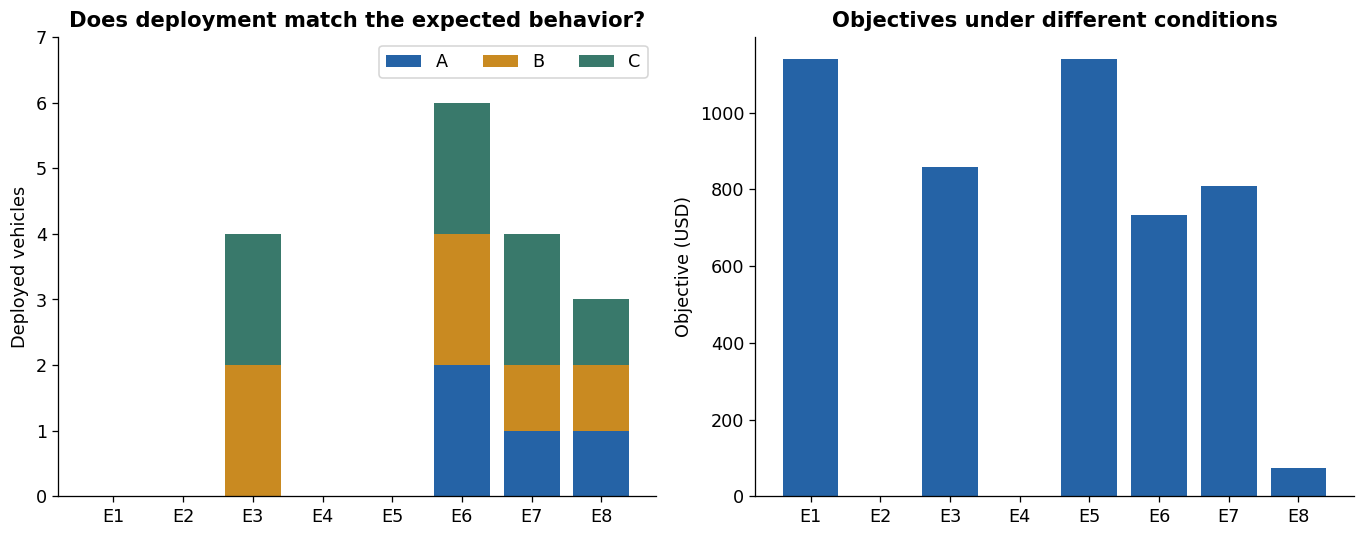

**E1~E8:** 차량 없음 / 수요 없음 / A 금지 / 미충족 손실 없음 / 큰 진입비 / Q=8 / 진입비 없음 / 수요=10.

**읽기:** E1·E4·E5 모두 배치는 0이지만 목적함수는 다릅니다. E4는 놓치는 수요의 평가계수 자체가 0이기 때문입니다. E6은 차량 한도를 늘려도 도시별 상한 때문에 6대에서 멈춥니다. 서로 다른 조건의 목적함수 크기를 사업 성과 순위로 읽으면 안 됩니다.

검사,조건,예상,구현검사,예상성질,배치,처리율,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
E1,가용 차량 없음,"미진입, q=0, U=D, 목적함수 1140",PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
E2,수요 없음,"미진입, 목적함수·O·U 모두 0",PASS,PASS,"(0, 0, 0)",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
E3,A 배치 금지,A의 y와 q는 0,PASS,PASS,"(0, 2, 2)",0.3000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
E4,미충족 손실 없음,"미진입, 목적함수 0",PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
E5,매우 큰 진입비,미진입,PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
E6,총차량 한도 완화,"q=(2,2,2), 실제 배치 6대",PASS,PASS,"(2, 2, 2)",0.4368,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
E7,진입비 없음,차량 배치 도시는 진입 상태,PASS,PASS,"(1, 1, 2)",0.3070,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
E8,수요=차량 1대 용량,"q=(1,1,1), O=U=0, 목적함수 75",PASS,PASS,"(1, 1, 1)",1.0000,60.0000,15.0000,0.0000,0.0000,75.0000,300.0000,225.0000


In [ ]:
sa_EDGE_CASES = [
    ('E1','가용 차량 없음', {'Q':0}, '미진입, q=0, U=D, 목적함수 1140'),
    ('E2','수요 없음', {'M':np.zeros(3)}, '미진입, 목적함수·O·U 모두 0'),
    ('E3','A 배치 금지', {'qbar':np.array([0,2,2])}, 'A의 y와 q는 0'),
    ('E4','미충족 손실 없음', {'c_minus':np.zeros(3)}, '미진입, 목적함수 0'),
    ('E5','매우 큰 진입비', {'F':np.full(3,10000.)}, '미진입'),
    ('E6','총차량 한도 완화', {'Q':8}, 'q=(2,2,2), 실제 배치 6대'),
    ('E7','진입비 없음', {'F':np.zeros(3)}, '차량 배치 도시는 진입 상태'),
    ('E8','수요=차량 1대 용량', {'p':np.tile(10/sa_BASE['M'],(10,1))},
     'q=(1,1,1), O=U=0, 목적함수 75')]

def sa_check_expected_result(case_id, answer):
    # 대표해뿐 아니라 모든 최적해가 해당 성질을 만족하는지 검사한다.
    for r in answer['optima']:
        none = r['q']==(0,0,0) and r['y']==(0,0,0)
        tests = {
            'E1': none and np.allclose(r['O'],0) and np.allclose(r['U'],r['D'])
                  and abs(r['cost']-1140)<sa_TOL,
            'E2': none and abs(r['cost'])<sa_TOL and np.allclose(r['O'],0) and np.allclose(r['U'],0),
            'E3': r['q'][0]==0 and r['y'][0]==0,
            'E4': none and abs(r['cost'])<sa_TOL,
            'E5': none,
            'E6': r['q']==(2,2,2) and r['y']==(1,1,1),
            'E7': all(y==1 for y,q in zip(r['y'],r['q']) if q>0),
            'E8': r['q']==(1,1,1) and np.allclose(r['D'],10)
                  and np.allclose(r['O'],0) and np.allclose(r['U'],0) and abs(r['cost']-75)<sa_TOL,
        }
        if not tests[case_id]: return False
    return True

sa_edge_results, sa_edge_rows = {}, []
for case_id,title,changes,expected in sa_EDGE_CASES:
    data = deepcopy(sa_BASE); data.update(deepcopy(changes))
    answer = sa_solve(data,case_id)
    expected_ok = sa_check_expected_result(case_id, answer)
    assert expected_ok, f'{case_id}: 예상 성질 불일치'
    sa_edge_results[case_id] = answer
    r = answer['rep']
    sa_edge_rows.append(dict(검사=case_id,조건=title,예상=expected,구현검사='PASS',
                          예상성질='PASS',배치=r['q'],처리율=r['service_rate'],
                          진입비=r['components'][0],차량비=r['components'][1],
                          유휴페널티=r['components'][2],미충족손실=r['components'][3],
                          목적함수=r['cost'],미진입기준=r['no_entry'],개선=r['gain']))
sa_cards([('구현 검사', '8 / 8 PASS'), ('예상 성질 검사', '8 / 8 PASS')])
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
edge_q = np.array([a['rep']['q'] for a in sa_edge_results.values()])
bottom = np.zeros(8)
for c in range(3):
    axes[0].bar(range(8),edge_q[:,c],bottom=bottom,color=CITY_COLORS[c],label=cities[c])
    bottom += edge_q[:,c]
axes[0].set_xticks(range(8),sa_edge_results.keys()); axes[0].set_ylim(0,7)
axes[0].set_ylabel(sa_L('배치 차량 (대)','Deployed vehicles')); axes[0].legend(ncols=3)
axes[0].set_title(sa_L('예상대로 배치가 달라지는가?', 'Does deployment match the expected behavior?'))
axes[1].bar(range(8),[a['cost'] for a in sa_edge_results.values()],color='#2563A6')
axes[1].set_xticks(range(8),sa_edge_results.keys()); axes[1].set_ylabel(sa_L('목적함수 (USD)','Objective (USD)'))
axes[1].set_title(sa_L('조건이 달라진 문제들의 목적함수', 'Objectives under different conditions'))
fig.tight_layout(); sa_showfig(fig,'04_edges')
sa_note('**E1~E8:** 차량 없음 / 수요 없음 / A 금지 / 미충족 손실 없음 / 큰 진입비 / '
     'Q=8 / 진입비 없음 / 수요=10.\n\n'
     '**읽기:** E1·E4·E5 모두 배치는 0이지만 목적함수는 다릅니다. E4는 놓치는 수요의 '
     '평가계수 자체가 0이기 때문입니다. E6은 차량 한도를 늘려도 도시별 상한 때문에 6대에서 멈춥니다. '
     '서로 다른 조건의 목적함수 크기를 사업 성과 순위로 읽으면 안 됩니다.')
sa_detail('E1~E8 조건과 예상 성질 확인',pd.DataFrame(sa_edge_rows))

## 3. 민감도 분석
매번 기준 입력을 복사하고 **하나의 파라미터만 변경한 뒤 다시 최적화**한다.

-결정의 민감도와 성과의 민감도 분석을 한다.
- 결정의 민감도 : "조건이나 파라미터가 바뀔 때, 최적의 의사결정(변수 값)이 실제로 변경되는가?"를 확인

- 성과의 민감도 : 결정의 변화 또는 외생적 변화에 따라 운영 시스템의 핵심 성과 지표(KPI)가 얼마나 영향을 받는가?"를 측정

- 분석 그래프는 **배치,  처리율,  목적함수 구성, 미진입 대비 개선** 으로 구성.
처리율과 개선은 해당 실험의 수요·계수로 계산합니다.


\

$$
\text{개선액}
=
Z_{\text{미진입}}-Z(y,q)
$$


$$
\text{처리율}(\%)
=
\frac{
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}\min(D_c^s,\kappa_c q_c)
}{
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}D_c^s
}
\times100
$$

$$
\begin{aligned}
\text{미진입 대비 개선액}
&=
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}c_c^-D_c^s\\
&\quad-
\left[
\sum_{c\in C}F_cy_c
+\sum_{c\in C}K_cq_c
+\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}
\left(c_c^+O_c^s+c_c^-U_c^s\right)
\right]
\end{aligned}
$$

음영은 **모든 최적해 사이의 범위**입니다. 배치는 고정된 규칙으로 고른 대표해이며,
처리율·개선·각 비용의 자세한 범위는 접힌 표에 보관됩니다.

In [ ]:
sa_experiments = {}
def sa_run_sweep(name, values, change):
    results = []
    for value in values:
        data = deepcopy(sa_BASE)
        change(data,float(value))
        answer = sa_solve(data,f'{name}={value:g}')
        results.append((float(value),answer))
    sa_experiments[name] = results
    return results

def sa_full_rows(results):
    rows = []
    for x,a in results:
        for i,r in enumerate(a['optima']):
            rows.append(dict(입력값=x,대표해=i==0,y=r['y'],q=r['q'],최적해수=len(a['optima']),
                처리율=r['service_rate'],처리량=r['served'],미충족=r['unmet'],미사용=r['unused'],
                진입비=r['components'][0],차량비=r['components'][1],유휴페널티=r['components'][2],
                미충족손실=r['components'][3],목적함수=r['cost'],미진입기준=r['no_entry'],개선=r['gain']))
    return pd.DataFrame(rows)

def sa_opt_label(a):
    return ' / '.join(str(q) for q in sorted({r['q'] for r in a['optima']}))

def sa_transition_notes(results):
    changes=[]
    for (x0,a0),(x1,a1) in zip(results,results[1:]):
        old={r['q'] for r in a0['optima']}; new={r['q'] for r in a1['optima']}
        if old != new:
            changes.append(f'- **{x0:g} → {x1:g}**: `{sa_opt_label(a0)}` → `{sa_opt_label(a1)}`')
    sa_note('**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):\n\n'
         +'\n'.join(changes) if changes else '**확인:** 시험한 범위에서 최적 배치 집합이 유지됩니다.')

def sa_plot_sweep(results, xlabel, title, filename, reference=None):
    xx=np.array([x for x,a in results]); rr=[a['rep'] for x,a in results]
    fig,axes=plt.subplots(2,2,figsize=(13,8.5))
    ax=axes[0,0]
    for c in range(3):
        vals=[r['q'][c] for r in rr]
        lows=[min(r['q'][c] for r in a['optima']) for x,a in results]
        highs=[max(r['q'][c] for r in a['optima']) for x,a in results]
        ax.plot(xx,vals,marker=['o','s','^'][c],markersize=4,color=CITY_COLORS[c],label=cities[c],
                linestyle=['-','--',':'][c])
        ax.fill_between(xx,lows,highs,color=CITY_COLORS[c],alpha=.10)

    ax.set_ylim(-.12,max(sum(sa_BASE['qbar']),max(sum(r['q']) for r in rr))/2+.2)
    ax.set_yticks(range(4)); ax.legend(ncols=3)
    ax.set_title(sa_L('① 도시별 배치: 선=대표해, 음영=동률 범위', '1. Vehicles: lines=representative, bands=ties'))
    ax.set_ylabel(sa_L('차량 (대)','Vehicles'))
    ax=axes[0,1]

    lows=[min(r['service_rate'] for r in a['optima'])*100 for x,a in results]
    highs=[max(r['service_rate'] for r in a['optima'])*100 for x,a in results]

    ax.plot(xx,[r['service_rate']*100 for r in rr],color='#2563A6',marker='o',markersize=4)
    ax.fill_between(xx,lows,highs,color='#2563A6',alpha=.15)
    ax.set_ylim(0,100); ax.set_ylabel('%')
    ax.set_title(sa_L('② 전체 후보 도시 수요의 처리율','2. Served share of demand across all candidate cities'))
    ax=axes[1,0]
    for j in range(4):
        ax.plot(xx,[r['components'][j] for r in rr],color=COST_COLORS[j] if j<3 else '#64748B',
                label=sa_component_labels[j],linestyle=['-','--',':','-.'][j])

    ax.plot(xx,[r['cost'] for r in rr],color='#172B40',linewidth=2.2,label=sa_L('합계','Total'))
    ax.set_ylim(bottom=0);ax.set_ylabel('USD');ax.legend(fontsize=9,ncols=2)
    ax.set_title(sa_L('③ 목적함수 구성 (기회손실 포함)','3. Objective components, including opportunity loss'))
    ax=axes[1,1]
    ax.plot(xx,[r['gain'] for r in rr],color='#39796B',marker='o',markersize=4)
    ax.axhline(0,color='#64748B',linewidth=.8);ax.set_ylim(bottom=0);ax.set_ylabel('USD')
    ax.set_title(sa_L('④ 같은 조건의 미진입 대비 개선','4. Improvement over no entry under the same conditions'))

    for ax in axes.flat:
        ax.set_xlabel(xlabel);ax.grid(axis='y',alpha=.18)
        if reference is not None:ax.axvline(reference,color='#64748B',linestyle=':',alpha=.7)
    fig.suptitle(title,fontsize=15)
    fig.text(.5,.01,sa_L('점은 실행값 · 선은 시각적 연결 · 음영은 복수 최적해 범위(신뢰구간 아님)',
                      'Points are evaluated settings; lines connect them. Bands show tied optima, not confidence intervals.'),
             ha='center',fontsize=10)
    fig.tight_layout(rect=[0,.04,1,.95]);sa_showfig(fig,filename)
    sa_transition_notes(results)
    sa_detail('전체 수치와 모든 동률 최적 배치 펼치기',sa_full_rows(results))

### 질문 1. 차량을 한 대 더 확보하면 얼마나 좋아지는가? — Q
Q는 반드시 배치할 차량 수가 아니라 **배치 가능한 상한**입니다.
Q=0~8을 한 대씩 증가시킵니다. 도시별 상한은 2대씩 유지합니다.

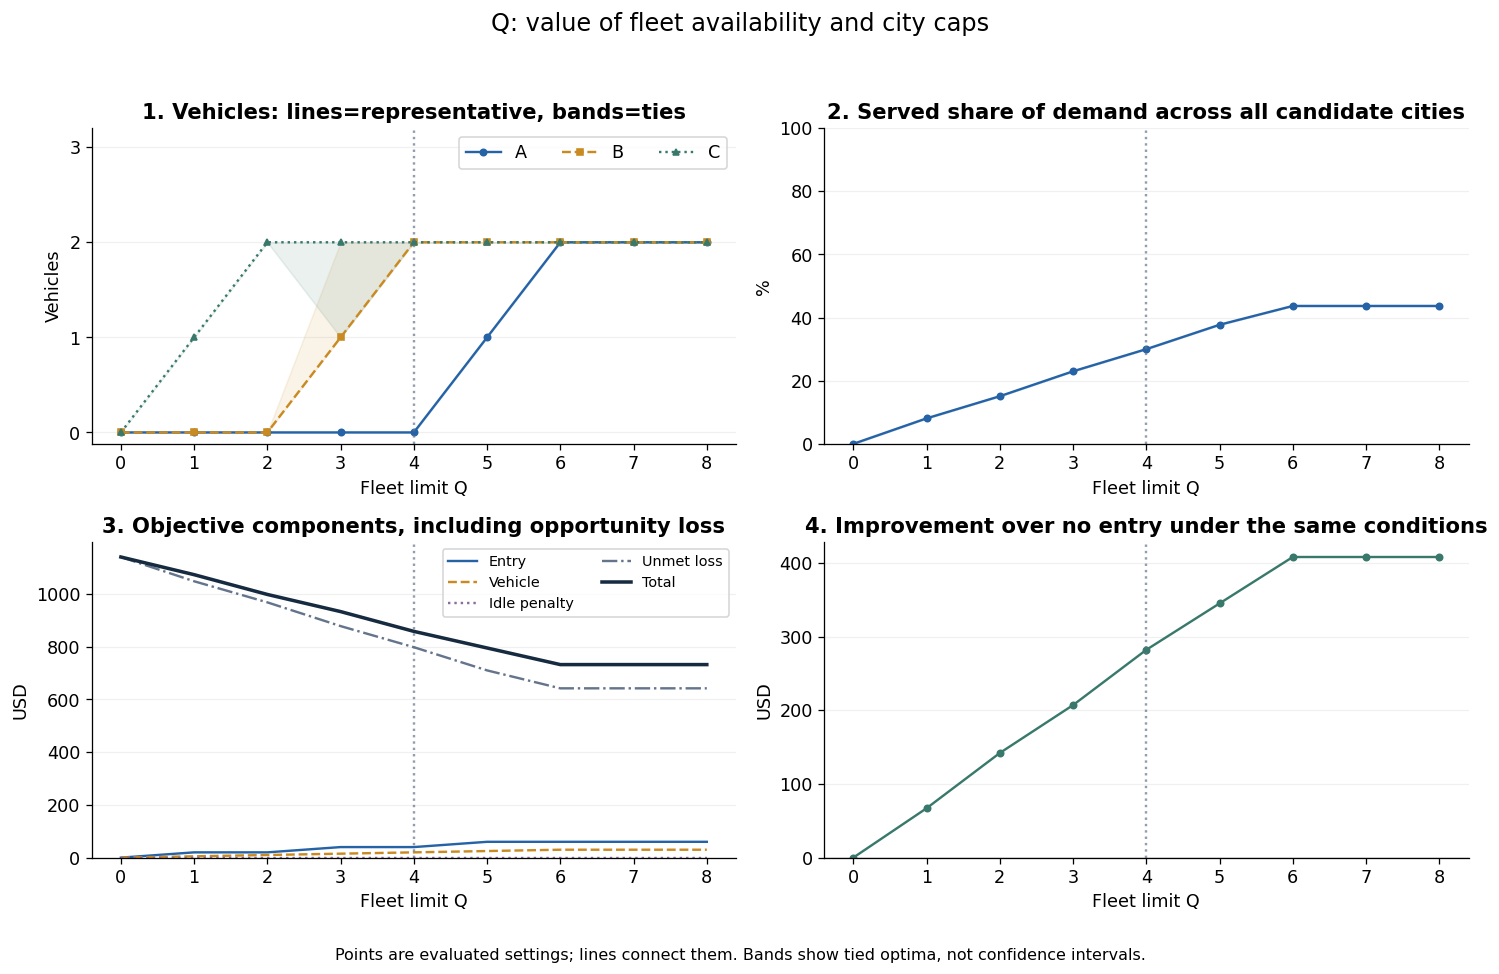

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **0 → 1**: `(0, 0, 0)` → `(0, 0, 1)`
- **1 → 2**: `(0, 0, 1)` → `(0, 0, 2)`
- **2 → 3**: `(0, 0, 2)` → `(0, 1, 2) / (0, 2, 1)`
- **3 → 4**: `(0, 1, 2) / (0, 2, 1)` → `(0, 2, 2)`
- **4 → 5**: `(0, 2, 2)` → `(1, 2, 2)`
- **5 → 6**: `(1, 2, 2)` → `(2, 2, 2)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.0000,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
1.0000,True,"(0, 0, 1)","(0, 0, 1)",1,0.0807,9.2000,104.8000,0.8000,20.0000,5.0000,0.0000,"1,048.0000","1,073.0000","1,140.0000",67.0000
2.0000,True,"(0, 0, 1)","(0, 0, 2)",1,0.1509,17.2000,96.8000,2.8000,20.0000,10.0000,0.0000,968.0000,998.0000,"1,140.0000",142.0000
3.0000,True,"(0, 1, 1)","(0, 1, 2)",2,0.2298,26.2000,87.8000,3.8000,40.0000,15.0000,0.0000,878.0000,933.0000,"1,140.0000",207.0000
3.0000,False,"(0, 1, 1)","(0, 2, 1)",2,0.2298,26.2000,87.8000,3.8000,40.0000,15.0000,0.0000,878.0000,933.0000,"1,140.0000",207.0000
4.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
5.0000,True,"(1, 1, 1)","(1, 2, 2)",1,0.3772,43.0000,71.0000,7.0000,60.0000,25.0000,0.0000,710.0000,795.0000,"1,140.0000",345.0000
6.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
7.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
8.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000


**해석:** Q=4에서 `[0,2,2]`, Q=5에서 `[1,2,2]`, Q=6에서 `[2,2,2]`가 됩니다. Q=4→5의 개선은 63 USD이며, Q=6 이후에는 도시별 상한 때문에 개선이 0입니다. 이 차이는 **주어진 차량비를 이미 반영한 추가 가용 차량의 모델 내 가치**입니다. 실제 차량 구매가격과 동일하게 해석하지 않습니다. Q=3에서는 `[0,1,2]`와 `[0,2,1]`이 동률입니다.

In [ ]:
sa_q_results=sa_run_sweep('Q',np.arange(9),lambda d,v:d.update(Q=int(v)))
sa_plot_sweep(sa_q_results,sa_L('총차량 한도 Q (대)','Fleet limit Q'),
           sa_L('Q: 차량 확보의 가치와 도시별 상한','Q: value of fleet availability and city caps'), '05_Q',4)
q_cost=np.array([a['cost'] for x,a in sa_q_results])
assert np.all(np.diff(q_cost)<=sa_TOL)
assert np.allclose(q_cost[6:],732)
sa_note('**해석:** Q=4에서 `[0,2,2]`, Q=5에서 `[1,2,2]`, Q=6에서 `[2,2,2]`가 됩니다. '
     'Q=4→5의 개선은 63 USD이며, Q=6 이후에는 도시별 상한 때문에 개선이 0입니다. '
     '이 차이는 **주어진 차량비를 이미 반영한 추가 가용 차량의 모델 내 가치**입니다. '
     '실제 차량 구매가격과 동일하게 해석하지 않습니다. Q=3에서는 `[0,1,2]`와 `[0,2,1]`이 동률입니다.')

### 질문 2. 진입비가 얼마일 때 집중·분산·미진입으로 바뀌는가? — F
모든 도시의 F를 같은 값으로 변경합니다. 먼저 0~20을 자세히 보고, 더 큰 값에서
사업을 하지 않는 선택까지 확인합니다. 특히 F=8의 전환은 두 전략의 비용식을 비교하여 정확히 확인합니다.

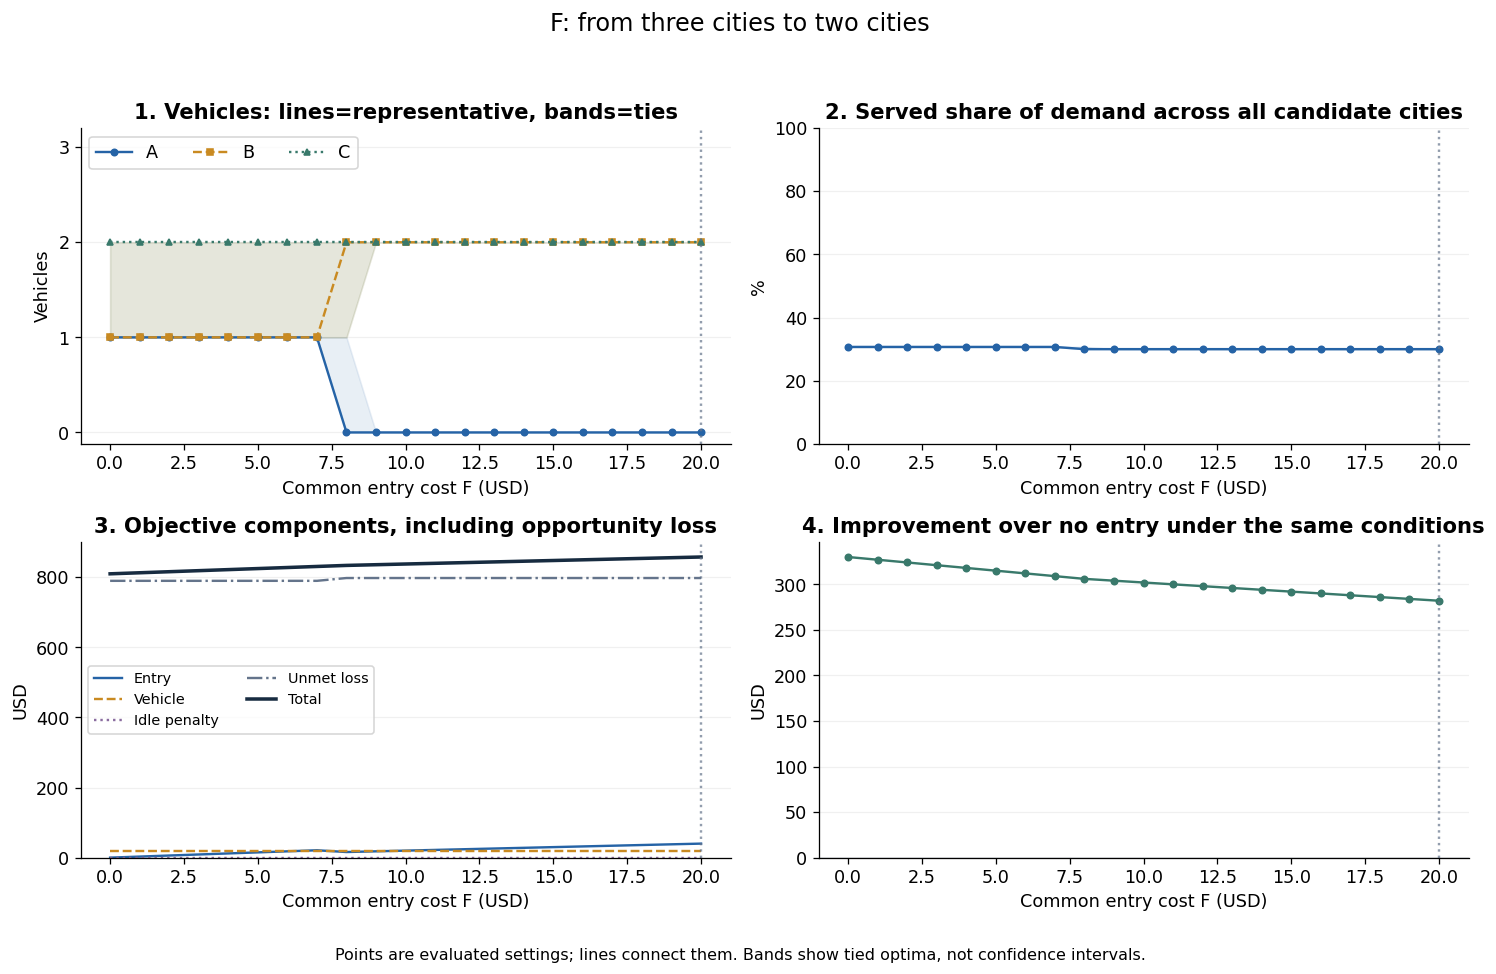

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **7 → 8**: `(1, 1, 2) / (1, 2, 1)` → `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)`
- **8 → 9**: `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)` → `(0, 2, 2)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
0.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
1.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
1.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
2.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
2.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
3.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
3.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
4.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000
4.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000


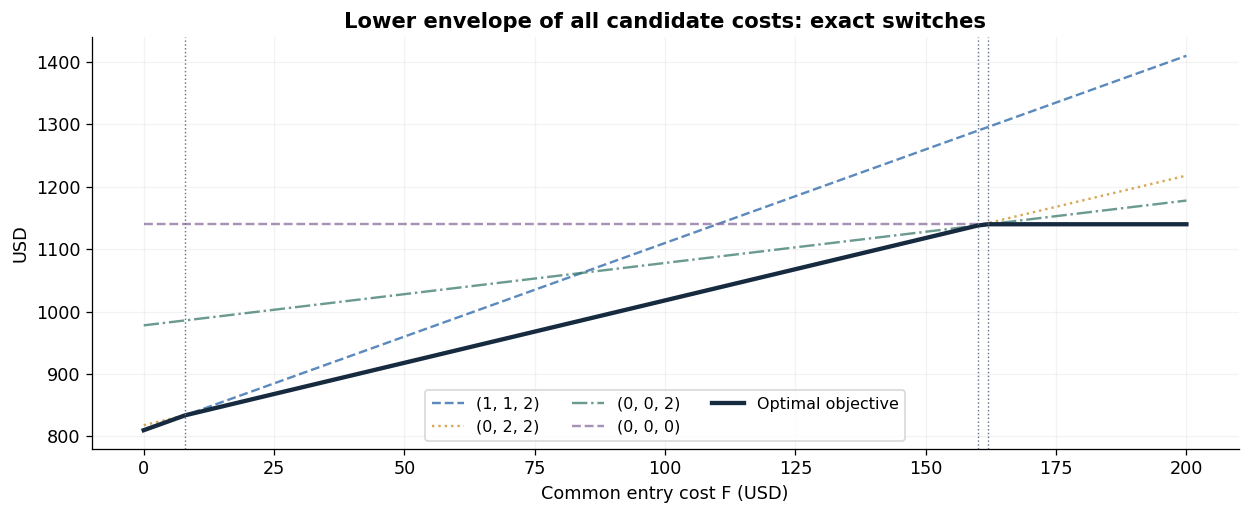

**정확한 비용식:** 세 도시 `[1,1,2]`는 `810+3F`, 두 도시 `[0,2,2]`는 `818+2F`입니다. 추가 처리의 가치 8과 추가 진입비가 같아지는 **F=8**에서 동률입니다. F가 8보다 조금 작으면 세 도시, 조금 크면 두 도시가 유리합니다.

**전체 후보 비용식으로 확인한 전환점:** 8, 160, 162 USD. 큰 진입비에서는 C만 진입한 뒤 최종적으로 미진입이 최적이 됩니다. 위 전체 범위 그림의 선은 각 고정 배치의 정확한 비용식입니다.

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **159 → 160**: `(0, 2, 2)` → `(0, 0, 2) / (0, 2, 2)`
- **160 → 161**: `(0, 0, 2) / (0, 2, 2)` → `(0, 0, 2)`
- **161 → 162**: `(0, 0, 2)` → `(0, 0, 0) / (0, 0, 2)`
- **162 → 163**: `(0, 0, 0) / (0, 0, 2)` → `(0, 0, 0)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
0.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
1.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
1.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
2.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
2.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
3.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
3.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
4.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000
4.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000


In [ ]:
f_values=sorted(set(list(np.arange(0,21,1))+[40,80,120,150,155,159,160,161,162,163,170,200]))
sa_f_results=sa_run_sweep('F',f_values,lambda d,v:d.update(F=np.full(3,v)))
sa_plot_sweep([r for r in sa_f_results if r[0]<=20], sa_L('도시별 공통 진입비 F (USD)','Common entry cost F (USD)'),
           sa_L('F: 세 도시 분산에서 두 도시 집중으로','F: from three cities to two cities'), '06_F_zoom',20)
# 진입비만 바뀌므로 각 배치의 비용은 a+b*F 형태다. 모든 후보 직선의 교점을 확인한다.
fzero=deepcopy(sa_BASE);fzero['F']=np.zeros(3)
lines=sa_enumerate_decisions(fzero)
crossings=set()
for r in lines:
    for t in lines:
        slope=sum(r['y'])-sum(t['y'])
        if slope:
            crossing=(t['cost']-r['cost'])/slope
            if 0<crossing<200:
                vals=[u['cost']+sum(u['y'])*crossing for u in lines]
                if abs(r['cost']+sum(r['y'])*crossing-min(vals))<sa_TOL:
                    crossings.add(round(crossing,9))
sa_f_thresholds=sorted(crossings)
fig,ax=plt.subplots(figsize=(11,4.6))
strategies=[((1,1,1),(1,1,2)),((0,1,1),(0,2,2)),((0,0,1),(0,0,2)),((0,0,0),(0,0,0))]
grid=np.linspace(0,200,401)
for i,(strategy_y,strategy_q) in enumerate(strategies):
    intercept=sa_evaluate(fzero,strategy_y,strategy_q)['cost']
    ax.plot(grid,intercept+sum(strategy_y)*grid,label=str(strategy_q),color=['#2563A6','#C98A21','#39796B','#8A6C9F'][i],
            linestyle=['--',':','-.','--'][i],alpha=.75)
envelope=np.min([[r['cost']+sum(r['y'])*v for v in grid] for r in lines],axis=0)
ax.plot(grid,envelope,color='#172B40',linewidth=2.7,label=sa_L('최적 목적함수','Optimal objective'))
for x in sa_f_thresholds:ax.axvline(x,color='#64748B',linewidth=.9,linestyle=':')
ax.set_xlabel(sa_L('공통 진입비 F (USD)','Common entry cost F (USD)'));ax.set_ylabel('USD')
ax.set_title(sa_L('모든 후보 비용식의 최솟값: 정확한 전략 전환','Lower envelope of all candidate costs: exact switches'))
ax.legend(ncols=3,fontsize=10);ax.grid(alpha=.15);fig.tight_layout();sa_showfig(fig,'07_F_full')
sa_note('**정확한 비용식:** 세 도시 `[1,1,2]`는 `810+3F`, 두 도시 `[0,2,2]`는 `818+2F`입니다. '
     '추가 처리의 가치 8과 추가 진입비가 같아지는 **F=8**에서 동률입니다. '
     'F가 8보다 조금 작으면 세 도시, 조금 크면 두 도시가 유리합니다.\n\n'
     '**전체 후보 비용식으로 확인한 전환점:** '+', '.join(f'{x:g}' for x in sa_f_thresholds)+' USD. '
     '큰 진입비에서는 C만 진입한 뒤 최종적으로 미진입이 최적이 됩니다. '
     '위 전체 범위 그림의 선은 각 고정 배치의 정확한 비용식입니다.')
sa_transition_notes([r for r in sa_f_results if r[0]>=20])
sa_detail('F 전체 범위: 배치·처리율·비용·미진입 대비 개선',sa_full_rows(sa_f_results))

### 질문 3. 차량 한 대의 처리량이 늘면 분산할 이유가 생기는가? — kappa
모든 도시의 kappa를 5~20에서 0.5 간격으로 변경합니다. 차량 수와 비용은 기준값을 유지합니다.
c_plus=0인 이 실험에서는 같은 배치의 용량을 늘려도 유휴 페널티가 추가되지 않아
최적 목적함수가 증가하지 않아야 합니다. c_plus>0인 다른 모형에 이 성질을 무조건 적용하면 안 됩니다.

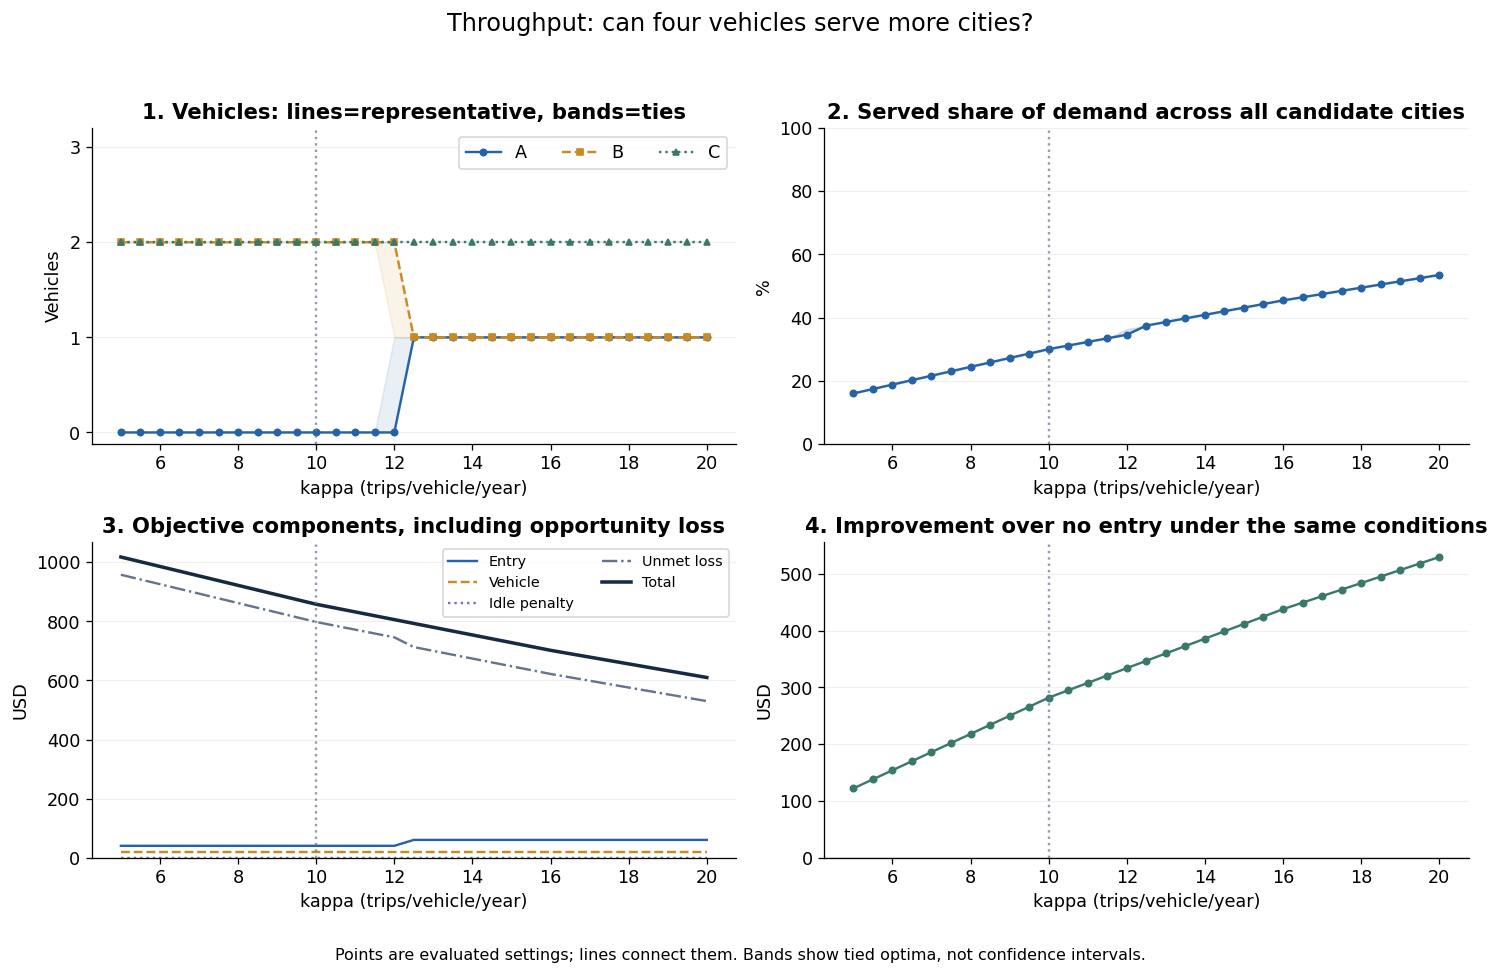

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **11.5 → 12**: `(0, 2, 2)` → `(0, 2, 2) / (1, 1, 2)`
- **12 → 12.5**: `(0, 2, 2) / (1, 1, 2)` → `(1, 1, 2)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
5.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,18.2000,95.8000,1.8000,40.0000,20.0000,0.0000,958.0000,"1,018.0000","1,140.0000",122.0000
5.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1737,19.8000,94.2000,2.2000,40.0000,20.0000,0.0000,942.0000,"1,002.0000","1,140.0000",138.0000
6.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1877,21.4000,92.6000,2.6000,40.0000,20.0000,0.0000,926.0000,986.0000,"1,140.0000",154.0000
6.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2018,23.0000,91.0000,3.0000,40.0000,20.0000,0.0000,910.0000,970.0000,"1,140.0000",170.0000
7.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2158,24.6000,89.4000,3.4000,40.0000,20.0000,0.0000,894.0000,954.0000,"1,140.0000",186.0000
7.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2298,26.2000,87.8000,3.8000,40.0000,20.0000,0.0000,878.0000,938.0000,"1,140.0000",202.0000
8.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2439,27.8000,86.2000,4.2000,40.0000,20.0000,0.0000,862.0000,922.0000,"1,140.0000",218.0000
8.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2579,29.4000,84.6000,4.6000,40.0000,20.0000,0.0000,846.0000,906.0000,"1,140.0000",234.0000
9.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2719,31.0000,83.0000,5.0000,40.0000,20.0000,0.0000,830.0000,890.0000,"1,140.0000",250.0000
9.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2860,32.6000,81.4000,5.4000,40.0000,20.0000,0.0000,814.0000,874.0000,"1,140.0000",266.0000


**해석:** kappa=10에서는 `[0,2,2]`, kappa=20에서는 `[1,1,2]`입니다. 생산성이 높아지면 B에 두 번째 차량을 두는 것보다 A에 첫 차량을 보내는 이득이 커질 수 있습니다. kappa=20의 처리율은 약 53.5%, 목적함수는 610입니다. 미사용 용량은 늘어도 처리 수요 역시 늘기 때문에 미사용량 하나만으로 비효율이라고 판단하지 않습니다. 실행점 kappa=12에서는 두 배치가 동률이며 12.5에서는 세 도시 배치가 최적입니다. 12 근처에서 A의 첫 차량은 평균 `0.8+0.8*kappa`건, B의 두 번째 차량은 `6+0.2*kappa`건을 추가 처리합니다. 따라서 B의 차량 한 대를 A로 바꿀 때의 순이득은 `10*(0.6*kappa-5.2)-20 = 6*kappa-72`이고 kappa=12에서 0입니다. 이 계산은 해당 수요 구간의 식이며 전체 kappa 범위에 그대로 적용하지 않습니다.

In [ ]:
sa_k_results=sa_run_sweep('kappa',np.arange(5,20.01,.5),lambda d,v:d.update(kappa=np.full(3,v)))
sa_plot_sweep(sa_k_results,sa_L('차량당 처리량 (건/대·년)','kappa (trips/vehicle/year)'),
           sa_L('kappa: 같은 4대로 더 넓게 서비스할 수 있는가?','Throughput: can four vehicles serve more cities?'),
           '08_kappa',10)
assert np.all(np.diff([a['cost'] for x,a in sa_k_results])<=sa_TOL)
assert sa_k_results[-1][1]['rep']['q']==(1,1,2)
sa_note('**해석:** kappa=10에서는 `[0,2,2]`, kappa=20에서는 `[1,1,2]`입니다. '
     '생산성이 높아지면 B에 두 번째 차량을 두는 것보다 A에 첫 차량을 보내는 이득이 커질 수 있습니다. '
     'kappa=20의 처리율은 약 53.5%, 목적함수는 610입니다. '
     '미사용 용량은 늘어도 처리 수요 역시 늘기 때문에 미사용량 하나만으로 비효율이라고 판단하지 않습니다. '
     '실행점 kappa=12에서는 두 배치가 동률이며 12.5에서는 세 도시 배치가 최적입니다. '
     '12 근처에서 A의 첫 차량은 평균 `0.8+0.8*kappa`건, B의 두 번째 차량은 '
     '`6+0.2*kappa`건을 추가 처리합니다. 따라서 B의 차량 한 대를 A로 바꿀 때의 '
     '순이득은 `10*(0.6*kappa-5.2)-20 = 6*kappa-72`이고 kappa=12에서 0입니다. '
     '이 계산은 해당 수요 구간의 식이며 전체 kappa 범위에 그대로 적용하지 않습니다.')

### 질문 4. A의 시장규모가 커지면 언제 A에 진입하는가? — M_A
A의 M만 기준 80의 0.5~2배로 바꾸고 B·C의 M과 모든 p는 그대로 둡니다.
이전의 모든 도시 동시 확대보다 **도시 선택의 변화**를 보기 쉬운 실험입니다.
M만 바꾸므로 수요의 평균과 변동 폭이 함께 변합니다. 순수 변동성 효과는 다음 질문에서 분리합니다.

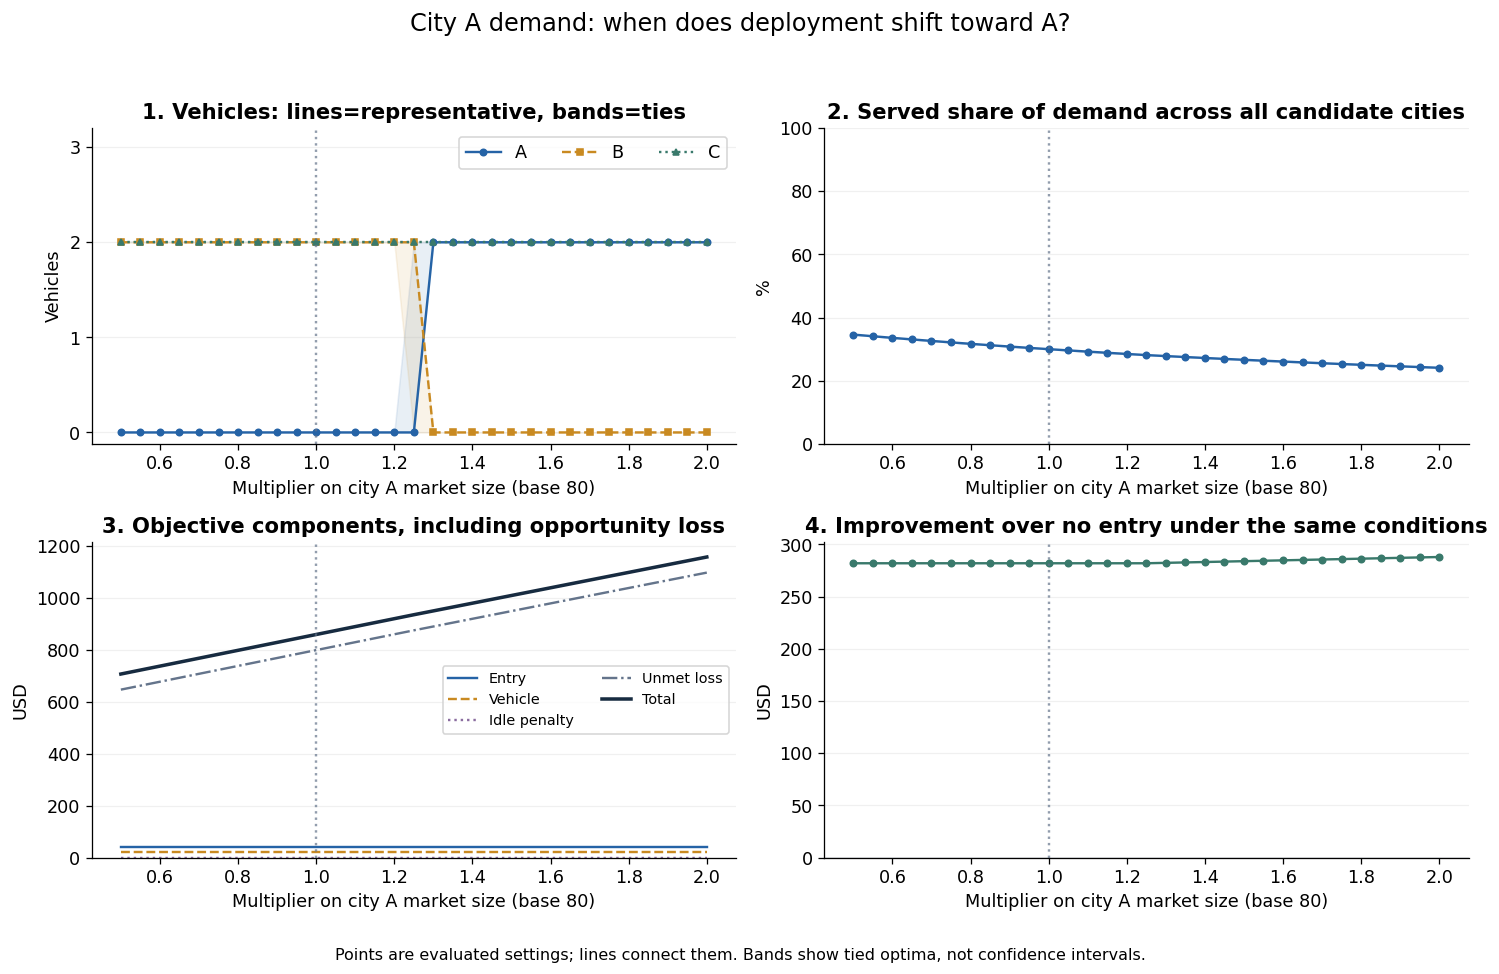

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **1.2 → 1.25**: `(0, 2, 2)` → `(0, 2, 2) / (2, 0, 2)`
- **1.25 → 1.3**: `(0, 2, 2) / (2, 0, 2)` → `(2, 0, 2)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3462,34.2000,64.6000,5.8000,40.0000,20.0000,0.0000,646.0000,706.0000,988.0000,282.0000
0.5500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3409,34.2000,66.1200,5.8000,40.0000,20.0000,0.0000,661.2000,721.2000,"1,003.2000",282.0000
0.6000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3358,34.2000,67.6400,5.8000,40.0000,20.0000,0.0000,676.4000,736.4000,"1,018.4000",282.0000
0.6500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3309,34.2000,69.1600,5.8000,40.0000,20.0000,0.0000,691.6000,751.6000,"1,033.6000",282.0000
0.7000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3261,34.2000,70.6800,5.8000,40.0000,20.0000,0.0000,706.8000,766.8000,"1,048.8000",282.0000
0.7500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3214,34.2000,72.2000,5.8000,40.0000,20.0000,0.0000,722.0000,782.0000,"1,064.0000",282.0000
0.8000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3169,34.2000,73.7200,5.8000,40.0000,20.0000,0.0000,737.2000,797.2000,"1,079.2000",282.0000
0.8500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3125,34.2000,75.2400,5.8000,40.0000,20.0000,0.0000,752.4000,812.4000,"1,094.4000",282.0000
0.9000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3082,34.2000,76.7600,5.8000,40.0000,20.0000,0.0000,767.6000,827.6000,"1,109.6000",282.0000
0.9500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3041,34.2000,78.2800,5.8000,40.0000,20.0000,0.0000,782.8000,842.8000,"1,124.8000",282.0000


**해석:** A의 시장규모가 **1.25배 (M_A=100)** 일 때 `[0,2,2]`와 `[2,0,2]`가 동률이고, **1.30배 (M_A=104)** 에서는 `[2,0,2]`가 최적입니다. B의 두 차량을 A로 옮기는 선택입니다. 1.25배에서는 A와 B의 M이 100으로 같아지고 p의 주변분포도 같으므로, 같은 차량 수의 기대 처리량과 비용이 같아집니다. 총차량 Q=4이므로 A의 수요가 늘어도 전체 차량이 자동으로 늘지는 않습니다. 수요 확대는 미진입 기준 손실도 키우므로, 목적함수 상승만으로 전략이 나빠졌다고 말할 수 없습니다. **처리율과 미진입 대비 개선을 함께** 읽어야 합니다.

In [ ]:
def sa_change_a(data,multiplier):
    data['M'][0]=sa_BASE['M'][0]*multiplier
sa_a_results=sa_run_sweep('M_A multiplier',np.round(np.arange(.5,2.001,.05),2),sa_change_a)
sa_plot_sweep(sa_a_results,sa_L('A의 M 배율 (기준 80)','Multiplier on city A market size (base 80)'),
           sa_L('M_A: A의 시장성이 좋아지면 어디서 차량을 가져오는가?',
             'City A demand: when does deployment shift toward A?'),'09_A_market',1)
sa_note('**해석:** A의 시장규모가 **1.25배 (M_A=100)** 일 때 `[0,2,2]`와 `[2,0,2]`가 동률이고, '
     '**1.30배 (M_A=104)** 에서는 `[2,0,2]`가 최적입니다. B의 두 차량을 A로 옮기는 선택입니다. '
     '1.25배에서는 A와 B의 M이 100으로 같아지고 p의 주변분포도 같으므로, '
     '같은 차량 수의 기대 처리량과 비용이 같아집니다. 총차량 Q=4이므로 A의 수요가 늘어도 전체 차량이 자동으로 늘지는 않습니다. '
     '수요 확대는 미진입 기준 손실도 키우므로, 목적함수 상승만으로 전략이 나빠졌다고 말할 수 없습니다. '
     '**처리율과 미진입 대비 개선을 함께** 읽어야 합니다.')

### 질문 5. A의 시장규모가 커지면 언제 A에 진입하는가? — M_A
세 도시의 \(c^+\)를 함께 0~20에서 0.5씩 증가시키고, 다른 입력은 고정한 채 매번 최적화해.

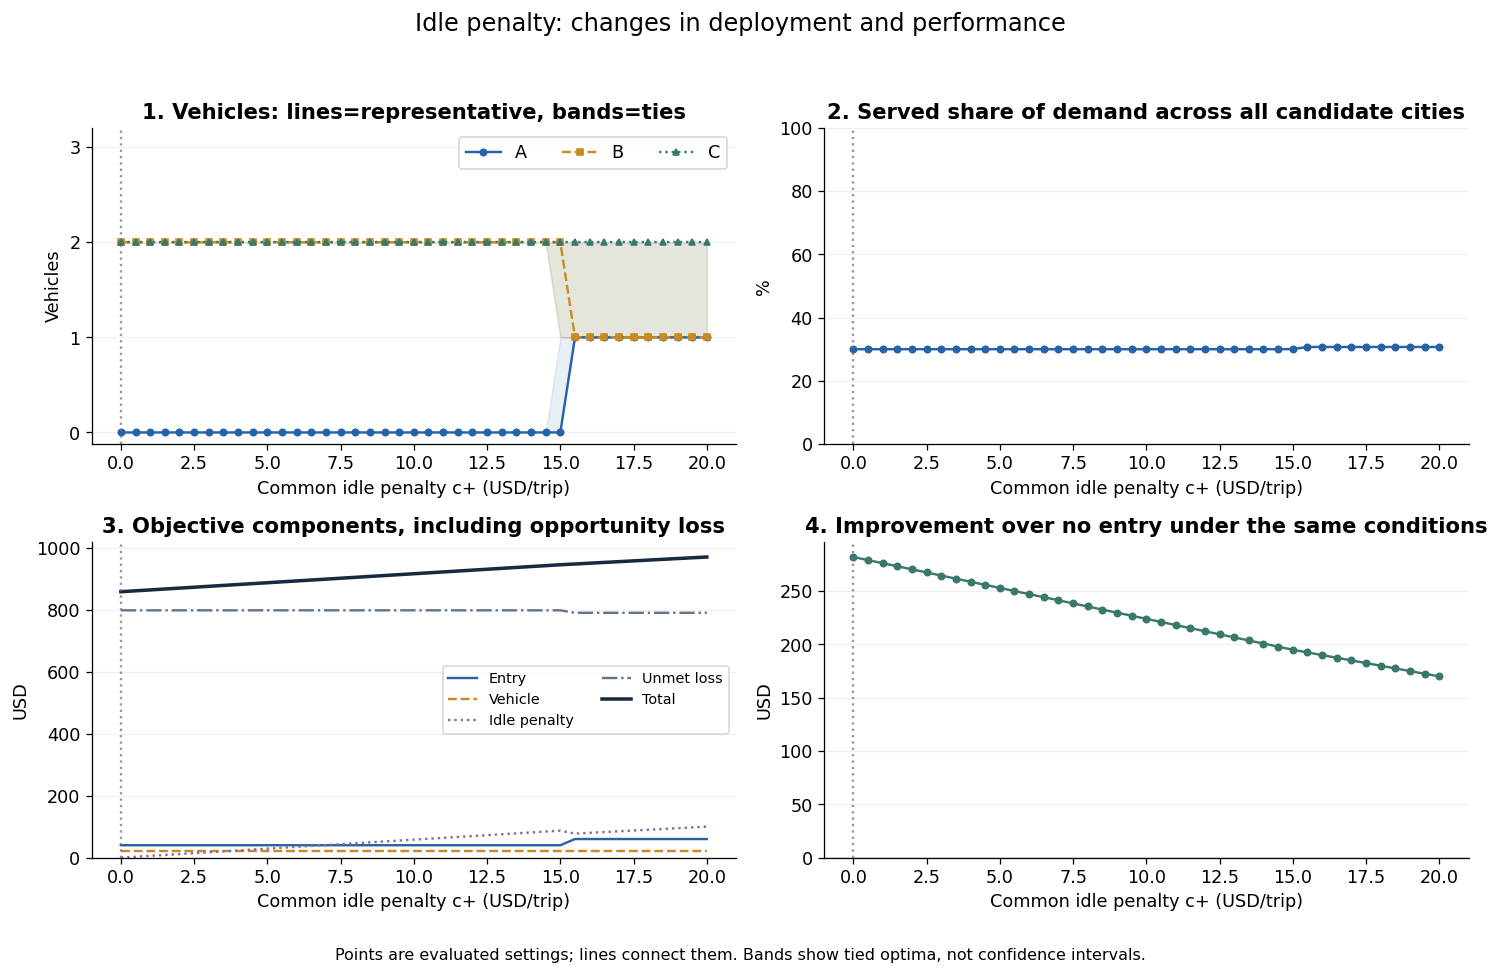

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **14.5 → 15**: `(0, 2, 2)` → `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)`
- **15 → 15.5**: `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)` → `(1, 1, 2) / (1, 2, 1)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
0.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,2.9000,798.0000,860.9000,"1,140.0000",279.1000
1.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,5.8000,798.0000,863.8000,"1,140.0000",276.2000
1.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,8.7000,798.0000,866.7000,"1,140.0000",273.3000
2.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,11.6000,798.0000,869.6000,"1,140.0000",270.4000
2.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,14.5000,798.0000,872.5000,"1,140.0000",267.5000
3.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,17.4000,798.0000,875.4000,"1,140.0000",264.6000
3.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,20.3000,798.0000,878.3000,"1,140.0000",261.7000
4.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,23.2000,798.0000,881.2000,"1,140.0000",258.8000
4.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,26.1000,798.0000,884.1000,"1,140.0000",255.9000



c+ 변화에 따른 배치와 운영 성과


,c+ (USD/건),"대표 배치 (A,B,C)",모든 최적 배치,평균 처리량,처리율 (%),평균 남는 용량
0,0.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
1,0.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
2,1.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
3,1.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
4,2.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
5,2.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
6,3.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
7,3.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
8,4.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
9,4.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8



c+ 변화에 따른 비용과 개선액 — 단위: USD


,c+ (USD/건),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 대비 개선
0,0.0,40.0,20.0,0.0,798.0,858.0,282.0
1,0.5,40.0,20.0,2.9,798.0,860.9,279.1
2,1.0,40.0,20.0,5.8,798.0,863.8,276.2
3,1.5,40.0,20.0,8.7,798.0,866.7,273.3
4,2.0,40.0,20.0,11.6,798.0,869.6,270.4
5,2.5,40.0,20.0,14.5,798.0,872.5,267.5
6,3.0,40.0,20.0,17.4,798.0,875.4,264.6
7,3.5,40.0,20.0,20.3,798.0,878.3,261.7
8,4.0,40.0,20.0,23.2,798.0,881.2,258.8
9,4.5,40.0,20.0,26.1,798.0,884.1,255.9



c+=0 대비 성과 변화


,c+ (USD/건),기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0,0.0,0.0,0.000,0.0,0.0
1,0.5,0.0,0.000,2.9,-2.9
2,1.0,0.0,0.000,5.8,-5.8
3,1.5,0.0,0.000,8.7,-8.7
4,2.0,0.0,0.000,11.6,-11.6
5,2.5,0.0,0.000,14.5,-14.5
6,3.0,0.0,0.000,17.4,-17.4
7,3.5,0.0,0.000,20.3,-20.3
8,4.0,0.0,0.000,23.2,-23.2
9,4.5,0.0,0.000,26.1,-26.1


※ 기준값이 0이므로 감소 실험 대신 0부터 양수로 증가시킵니다.
※ 배치가 유지되어도 유휴 페널티와 개선액은 달라질 수 있습니다.
※ 표의 성과는 대표 최적해 기준이며, 그래프 아래 상세표에는 모든 최적해가 있습니다.
※ 배치가 바뀌는 구간이 발견되면 그 구간의 간격을 줄여 추가 분석할 수 있습니다.


In [ ]:
# c_plus 민감도 분석
# 변경: 세 도시의 유휴 용량 1건당 페널티를 동일하게 변경
# 예: [0,0,0] → [0.5,0.5,0.5] → ... → [20,20,20]
# 고정: M, p, kappa, qbar, Q, F, K, c_minus
# 각 설정마다 다시 최적화합니다.

cplus_values = np.arange(0.0, 20.01, 0.5)

def change_cplus(data, value):
    data["c_plus"] = np.full_like(
        data["c_plus"], value, dtype=float
    )

cplus_results = sa_run_sweep(
    "c_plus",
    cplus_values,
    change_cplus,
)

# 기존 민감도 분석과 동일한 4개 그래프
# 최적 배치가 바뀌는 구간과 모든 최적해의 상세표도 출력
sa_plot_sweep(
    cplus_results,
    sa_L(
        "공통 유휴 페널티 c+ (USD/건)",
        "Common idle penalty c+ (USD/trip)",
    ),
    sa_L(
        "c+: 남는 용량에 비용을 부과하면 배치와 성과가 달라지는가?",
        "Idle penalty: changes in deployment and performance",
    ),
    "13_cplus",
    reference=0,
)

# c_plus=0인 경우를 기준으로 성과 차이 계산
cplus_reference = cplus_results[0][1]["rep"]
cplus_rows = []

for value, answer in cplus_results:
    metrics = answer["rep"]

    cplus_rows.append({
        "c+ (USD/건)": value,
        "대표 배치 (A,B,C)": metrics["q"],
        "모든 최적 배치": sa_opt_label(answer),
        "평균 처리량": metrics["served"],
        "처리율 (%)": 100 * metrics["service_rate"],
        "평균 남는 용량": metrics["unused"],
        "진입비": metrics["components"][0],
        "차량비": metrics["components"][1],
        "유휴 페널티": metrics["components"][2],
        "미충족 손실": metrics["components"][3],
        "목적함수": metrics["cost"],
        "미진입 대비 개선": metrics["gain"],
        "기준 대비 처리량 변화":
            metrics["served"] - cplus_reference["served"],
        "기준 대비 처리율 변화 (%p)":
            100 * (
                metrics["service_rate"]
                - cplus_reference["service_rate"]
            ),
        "기준 대비 목적함수 변화":
            metrics["cost"] - cplus_reference["cost"],
        "기준 대비 개선액 변화":
            metrics["gain"] - cplus_reference["gain"],
    })

cplus_summary = pd.DataFrame(cplus_rows)

show(
    "c+ 변화에 따른 배치와 운영 성과",
    cplus_summary[[
        "c+ (USD/건)",
        "대표 배치 (A,B,C)",
        "모든 최적 배치",
        "평균 처리량",
        "처리율 (%)",
        "평균 남는 용량",
    ]].round(3),
)

show(
    "c+ 변화에 따른 비용과 개선액 — 단위: USD",
    cplus_summary[[
        "c+ (USD/건)",
        "진입비",
        "차량비",
        "유휴 페널티",
        "미충족 손실",
        "목적함수",
        "미진입 대비 개선",
    ]].round(3),
)

show(
    "c+=0 대비 성과 변화",
    cplus_summary[[
        "c+ (USD/건)",
        "기준 대비 처리량 변화",
        "기준 대비 처리율 변화 (%p)",
        "기준 대비 목적함수 변화",
        "기준 대비 개선액 변화",
    ]].round(3),
)

# 같은 배치의 유휴 비용은 c_plus가 커질수록 증가하므로,
# 다시 최적화하더라도 최소 목적함수는 감소할 수 없습니다.
assert np.all(
    np.diff(cplus_summary["목적함수"].to_numpy()) >= -sa_TOL
), "c+ 증가에 따른 목적함수 변화를 확인하세요."

print("※ 기준값이 0이므로 감소 실험 대신 0부터 양수로 증가시킵니다.")
print("※ 배치가 유지되어도 유휴 페널티와 개선액은 달라질 수 있습니다.")
print("※ 표의 성과는 대표 최적해 기준이며, 그래프 아래 상세표에는 모든 최적해가 있습니다.")
print("※ 배치가 바뀌는 구간이 발견되면 그 구간의 간격을 줄여 추가 분석할 수 있습니다.")

### 질문 5. 평균은 같아도 변동성이 커지면 무엇이 달라지는가? — alpha
$$p(\alpha)=\bar p+\alpha(p-\bar p),\qquad 0\le\alpha\le1.$$
alpha=0은 평균만 있는 상황, 1은 원래 시나리오입니다. 같은 10개 시나리오의
변동 폭만 조정하며 시나리오 수·평균·발생확률은 유지합니다. 수요를 새로 표본추출하지 않습니다.

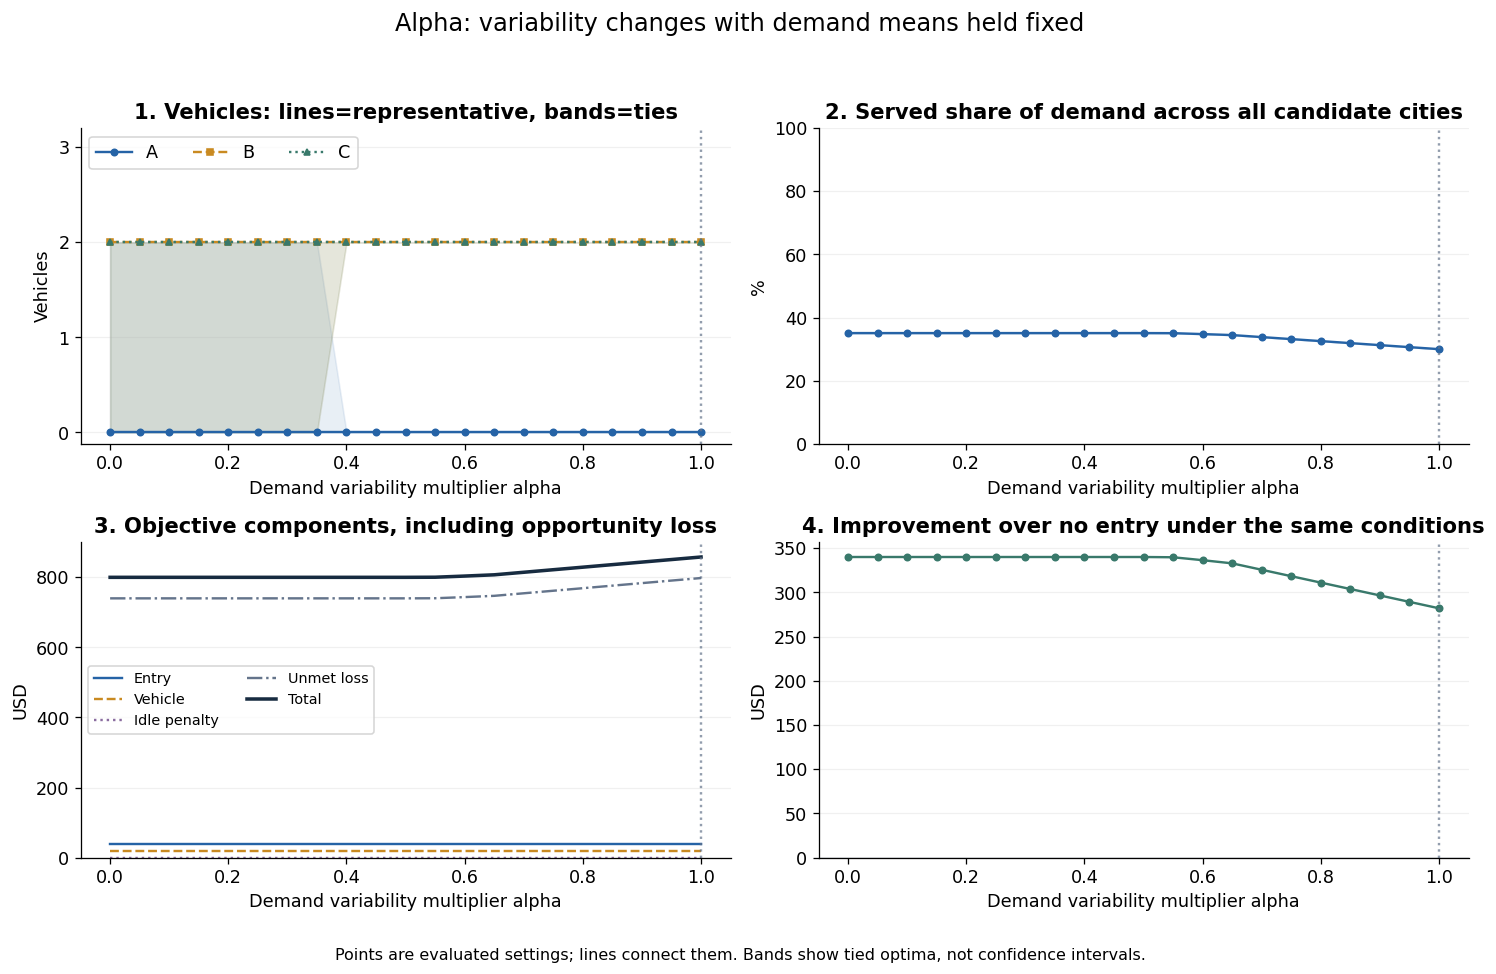

**실행점에서 최적 배치 집합이 바뀐 구간** (정확한 임계값은 아님):

- **0.35 → 0.4**: `(0, 2, 2) / (2, 0, 2) / (2, 2, 0)` → `(0, 2, 2)`

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선
0.0000,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0000,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0000,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1500,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000


**해석:** alpha=0에서는 세 가지 두 도시 배치가 동률입니다. 원래 변동성 alpha=1에서는 `[0,2,2]`만 최적이며 목적함수가 800에서 858로 증가합니다. 대표 배치가 같더라도 **동률 해의 범위와 운영 성과**는 달라질 수 있습니다. 이 사례에서는 변동성이 커지면서 차량이 남는 상황과 수요를 놓치는 상황이 함께 생깁니다.

In [ ]:
sa_mean_p=sa_BASE['p'].mean(axis=0,keepdims=True)
def sa_change_alpha(data,alpha):
    data['p']=sa_mean_p+alpha*(sa_BASE['p']-sa_mean_p)
    assert np.allclose(data['p'].mean(axis=0),sa_mean_p.ravel(),atol=1e-12,rtol=0)
sa_alpha_results=sa_run_sweep('alpha',np.round(np.linspace(0,1,21),2),sa_change_alpha)
sa_plot_sweep(sa_alpha_results,sa_L('수요 변동 배율 alpha','Demand variability multiplier alpha'),
           sa_L('alpha: 평균 수요를 고정한 변동성 실험','Alpha: variability changes with demand means held fixed'),
           '10_alpha',1)
assert np.all(np.diff([a['cost'] for x,a in sa_alpha_results])>=-sa_TOL)
sa_note('**해석:** alpha=0에서는 세 가지 두 도시 배치가 동률입니다. 원래 변동성 alpha=1에서는 '
     '`[0,2,2]`만 최적이며 목적함수가 800에서 858로 증가합니다. '
     '대표 배치가 같더라도 **동률 해의 범위와 운영 성과**는 달라질 수 있습니다. '
     '이 사례에서는 변동성이 커지면서 차량이 남는 상황과 수요를 놓치는 상황이 함께 생깁니다.')

## 4. 평균 수요만 보고 결정하면 무엇을 놓치는가?
평균 수요 문제로 구한 배치를 고정한 뒤, 시나리오 방식과 **동일한 평가 시나리오**에서 다시 평가합니다.
평균 수요 문제 자체의 목적함수 800을 변동 수요의 목적함수 858과 바로 비교하지 않습니다.
평균 수요 문제의 모든 동률 최적해를 평가하여, 사후에 유리하거나 불리한 하나만 고르는 것을 피합니다.

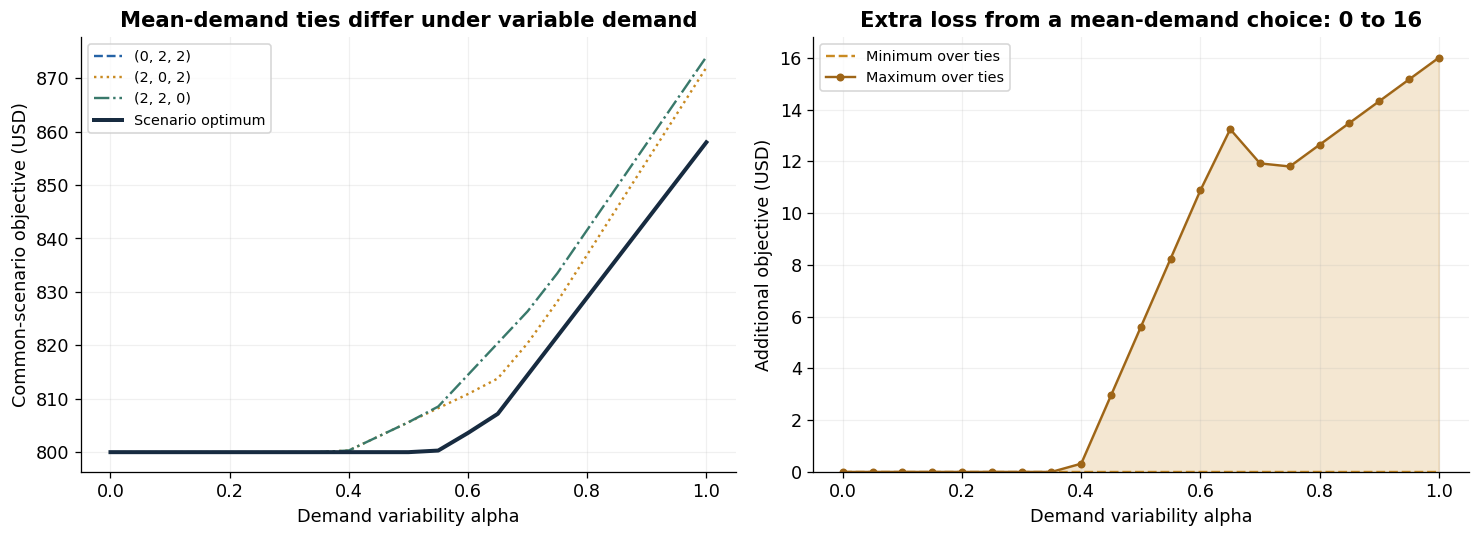

**결론:** alpha=1에서 평균 수요 방식의 배치는 평가 목적함수 **858·872·874**를 냅니다. 시나리오 최적값은 **858**입니다. 따라서 추가 손실은 **0~16**이며 “항상 16을 절감했다”는 뜻이 아닙니다. 음영은 **동률 배치의 성과 범위**로 신뢰구간이 아닙니다. 중간 구간에서 추가 손실이 잠깐 줄어드는 것은 오류가 아닙니다. 두 방법의 비용이 각각 변하기 때문에 **그 차이**가 변동성과 함께 항상 증가할 필요는 없습니다. 이 비교는 설계한 동일 시나리오 안의 비교이며 외부 표본에 대한 성능 검증은 아닙니다.

alpha,q,cost,gap,service_rate,gain,entry,vehicle,idle,unmet_loss
0.0000,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0000,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0000,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1500,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000


In [ ]:
sa_mean_data=deepcopy(sa_BASE);sa_mean_data['p']=sa_mean_p.copy()
sa_mean_answer=sa_solve(sa_mean_data,'mean-demand decision')
sa_comparison=[]
for alpha,a in sa_alpha_results:
    evaluated=[sa_evaluate(a['data'],r['y'],r['q']) for r in sa_mean_answer['optima']]
    for r in evaluated:
        gap=r['cost']-a['cost'];assert gap>=-sa_TOL
        sa_comparison.append(dict(alpha=alpha,q=r['q'],cost=r['cost'],gap=max(0.,gap),
            service_rate=r['service_rate'],gain=r['gain'],entry=r['components'][0],
            vehicle=r['components'][1],idle=r['components'][2],unmet_loss=r['components'][3]))
sa_comparison_df=pd.DataFrame(sa_comparison)
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for i,(plot_q,group) in enumerate(sa_comparison_df.groupby('q',sort=True)):
    axes[0].plot(group.alpha,group.cost,label=f'{plot_q}',color=CITY_COLORS[i],
                 linestyle=['--',':','-.'][i])
xx=[v for v,a in sa_alpha_results]; opt=[a['cost'] for v,a in sa_alpha_results]
axes[0].plot(xx,opt,color='#172B40',linewidth=2.5,label=sa_L('시나리오 최적','Scenario optimum'))
axes[0].set_ylabel(sa_L('공통 시나리오 평가 목적함수 (USD)','Common-scenario objective (USD)'))
axes[0].set_title(sa_L('평균 수요의 동률 배치들은 실제 평가에서 다르다',
                   'Mean-demand ties differ under variable demand'))
axes[0].legend(fontsize=9)
bounds=sa_comparison_df.groupby('alpha')['gap'].agg(['min','max'])
axes[1].fill_between(bounds.index,bounds['min'],bounds['max'],color='#C98A21',alpha=.2)
axes[1].plot(bounds.index,bounds['min'],color='#C98A21',linestyle='--',label=sa_L('동률 해 중 최소','Minimum over ties'))
axes[1].plot(bounds.index,bounds['max'],color='#9E6517',marker='o',markersize=4,label=sa_L('동률 해 중 최대','Maximum over ties'))
axes[1].set_ylim(bottom=0);axes[1].set_ylabel(sa_L('추가 목적함수 (USD)','Additional objective (USD)'))
axes[1].set_title(sa_L('평균 수요 방식의 추가 손실: 0~16', 'Extra loss from a mean-demand choice: 0 to 16'))
axes[1].legend(fontsize=9)
for ax in axes:ax.set_xlabel(sa_L('수요 변동 배율 alpha','Demand variability alpha'));ax.grid(alpha=.18)
fig.tight_layout();sa_showfig(fig,'11_mean_comparison')
assert np.isclose(bounds.loc[1.,'min'],0) and np.isclose(bounds.loc[1.,'max'],16)
sa_note('**결론:** alpha=1에서 평균 수요 방식의 배치는 평가 목적함수 **858·872·874**를 냅니다. '
     '시나리오 최적값은 **858**입니다. 따라서 추가 손실은 **0~16**이며 '
     '“항상 16을 절감했다”는 뜻이 아닙니다. 음영은 **동률 배치의 성과 범위**로 신뢰구간이 아닙니다. '
     '중간 구간에서 추가 손실이 잠깐 줄어드는 것은 오류가 아닙니다. 두 방법의 비용이 '
     '각각 변하기 때문에 **그 차이**가 변동성과 함께 항상 증가할 필요는 없습니다. '
     '이 비교는 설계한 동일 시나리오 안의 비교이며 외부 표본에 대한 성능 검증은 아닙니다.')
sa_detail('평균 수요 방식의 모든 배치: 처리율·비용 분해·개선',sa_comparison_df)

## 5. 원본의 나머지 민감도 실험도 유지
원본의 8개 파라미터 × 3수준(24행)은 아래에서 모두 재실행합니다.
본문에서는 전환점을 살펴볼 수 있는 다섯 질문을 우선했고, 기존 실험은 재현 확인과 보조 분석으로 남겼습니다.
그림은 기준값을 포함한 세 점만 연결합니다. 점 사이에서 어떤 변화가 있었는지는 추가 실험 없이 알 수 없습니다.

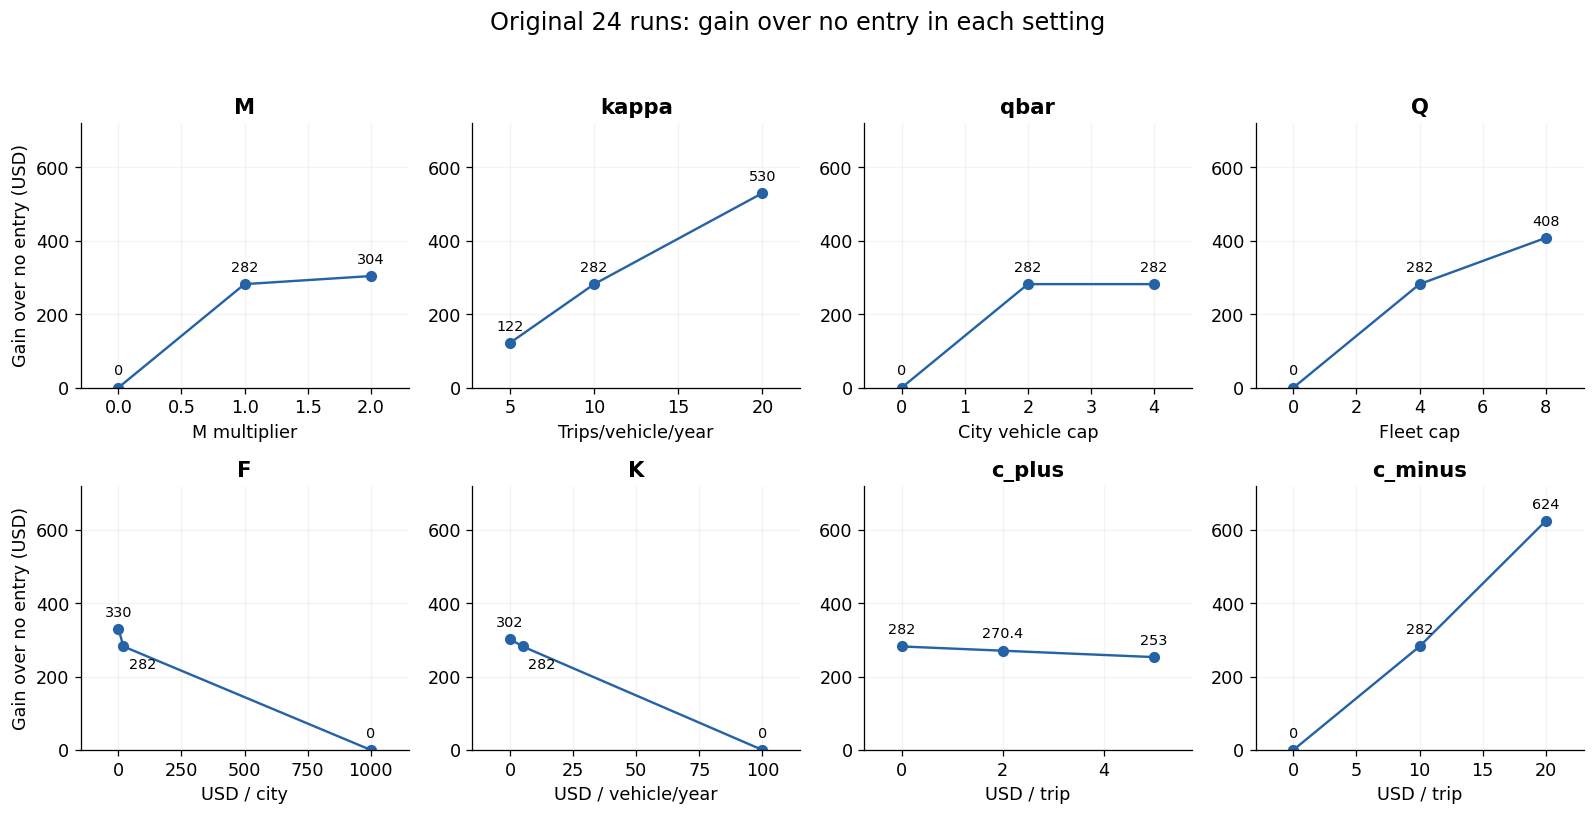

입력값,대표해,y,q,최적해수,처리율,처리량,미충족,미사용,진입비,차량비,유휴페널티,미충족손실,목적함수,미진입기준,개선,파라미터
0,True,"(0, 0, 0)","(0, 0, 0)",1,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,M
1,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,M
2,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,36.4000,191.6000,3.6000,40.0000,20.0000,0.0000,"1,916.0000","1,976.0000","2,280.0000",304.0000,M
5,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,18.2000,95.8000,1.8000,40.0000,20.0000,0.0000,958.0000,"1,018.0000","1,140.0000",122.0000,kappa
10,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,kappa
20,True,"(1, 1, 1)","(1, 1, 2)",1,0.5351,61.0000,53.0000,19.0000,60.0000,20.0000,0.0000,530.0000,610.0000,"1,140.0000",530.0000,kappa
0,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000,qbar
2,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,qbar
4,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,qbar
0,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000,Q


**해석:** M을 두 배로 늘리면 목적함수는 커지지만, 미진입 대비 개선은 282→304로 증가합니다. 도시별 상한 2→4는 개선이 없고, K=100에서는 진입하지 않습니다. c_plus=0·2·5에서는 배치가 유지되지만 유휴 페널티 때문에 개선은 작아집니다. c_minus를 바꾸면 같은 미충족 통행의 평가액이 달라지므로 다른 계수끼리의 목적함수 순위를 서비스 성과 순위로 읽으면 안 됩니다. M=0의 처리율은 0%가 아니라 미정의(NaN)입니다.

In [ ]:
sa_original_levels={
 'M':[(0,np.zeros(3)),(1,sa_BASE['M']),(2,sa_BASE['M']*2)],
 'kappa':[(5,np.full(3,5.)),(10,np.full(3,10.)),(20,np.full(3,20.))],
 'qbar':[(0,np.zeros(3,dtype=int)),(2,np.full(3,2)),(4,np.full(3,4))],
 'Q':[(0,0),(4,4),(8,8)],
 'F':[(0,np.zeros(3)),(20,np.full(3,20.)),(1000,np.full(3,1000.))],
 'K':[(0,np.zeros(3)),(5,np.full(3,5.)),(100,np.full(3,100.))],
 'c_plus':[(0,np.zeros(3)),(2,np.full(3,2.)),(5,np.full(3,5.))],
 'c_minus':[(0,np.zeros(3)),(10,np.full(3,10.)),(20,np.full(3,20.))]}
sa_original_expected={'M':[0,858,1976],'kappa':[1018,858,610],'qbar':[1140,858,858],
                   'Q':[1140,858,732],'F':[810,858,1140],'K':[838,858,1140],
                   'c_plus':[858,869.6,887],'c_minus':[0,858,1656]}
sa_original_results={}
for key,levels in sa_original_levels.items():
    results=[]
    for (value,new),expected in zip(levels,sa_original_expected[key]):
        data=deepcopy(sa_BASE);data[key]=deepcopy(new)
        answer=sa_solve(data,f'original {key}={value}')
        assert abs(answer['cost']-expected)<sa_TOL
        results.append((value,answer))
    sa_original_results[key]=results
fig,axes=plt.subplots(2,4,figsize=(14,7.2))
original_xlabel={'M':sa_L('M 배율','M multiplier'),'kappa':sa_L('건/대·년','Trips/vehicle/year'),
                 'qbar':sa_L('도시당 대수','City vehicle cap'),'Q':sa_L('총 대수','Fleet cap'),
                 'F':'USD / city','K':'USD / vehicle/year','c_plus':'USD / trip','c_minus':'USD / trip'}
for ax,(key,results) in zip(axes.flat,sa_original_results.items()):
    values=[x for x,a in results]; reps=[a['rep'] for x,a in results]
    ax.plot(values,[r['gain'] for r in reps],marker='o',color='#2563A6')
    ax.set_title(key);ax.set_xlabel(original_xlabel[key])
    ax.set_ylim(0,720);ax.grid(alpha=.15)
    for i,(x,r) in enumerate(zip(values,reps)):
        offset=(0,8)
        if key in ['F','K'] and i==1: offset=(12,-14)
        ax.annotate(f"{r['gain']:g}",(x,r['gain']),xytext=offset,textcoords='offset points',ha='center',fontsize=9)
    ax.margins(x=.15)
for ax in axes[:,0]:ax.set_ylabel(sa_L('미진입 대비 개선 (USD)','Gain over no entry (USD)'))
fig.suptitle(sa_L('원본 24개 실험: 각 조건의 미진입 대비 개선', 'Original 24 runs: gain over no entry in each setting'),fontsize=15)
fig.tight_layout(rect=[0,0,1,.95]);sa_showfig(fig,'12_original_sweeps')
sa_original_table=pd.concat([sa_full_rows(r).assign(파라미터=k) for k,r in sa_original_results.items()],ignore_index=True)
sa_detail('원본 24개 설정과 모든 최적 배치 확인',sa_original_table)
sa_note('**해석:** M을 두 배로 늘리면 목적함수는 커지지만, 미진입 대비 개선은 282→304로 증가합니다. '
     '도시별 상한 2→4는 개선이 없고, K=100에서는 진입하지 않습니다. '
     'c_plus=0·2·5에서는 배치가 유지되지만 유휴 페널티 때문에 개선은 작아집니다. '
     'c_minus를 바꾸면 같은 미충족 통행의 평가액이 달라지므로 다른 계수끼리의 목적함수 순위를 '
     '서비스 성과 순위로 읽으면 안 됩니다. M=0의 처리율은 0%가 아니라 미정의(NaN)입니다.')

## 6. 지금까지 무엇을 확인했는가?
1. **구현 정확성:** 기본해는 `(0,2,2)`, 목적함수 858이며 독립 전수계산과 일치합니다.
2. **모델 행동:** 추가 도시의 서비스 가치 8보다 진입비 20이 커서 두 도시에 집중합니다.
3. **자원 제약:** Q=6 이후에는 도시별 상한 때문에 차량을 더 확보해도 개선되지 않습니다.
4. **생산성:** kappa가 10에서 20으로 증가하면 세 도시 배치가 유리해집니다.
5. **불확실성:** 평균 수요에서 동률인 배치가 변동 수요에서는 서로 다른 성과를 보입니다.

**범위:** 검증한 합성 사례의 구현과 행동에 대한 결과입니다. 실제 시장의 최적 차량 수에 대한 권고는 아닙니다.
새로운 수요·공급 규모의 사례와 문헌 참고 규모 실험은 보류합니다.

**다음에 Overleaf에 옮길 내용:** 모델 설명, 입력과 단위, 기본해의 비용 논리, 예상 성질 검사,
다섯 민감도 질문, 평균 수요 방식의 동률 해 해석입니다. 현재 파일은 Overleaf를 변경하지 않습니다.

In [ ]:
assert all(all(run['checks'].values()) for run in sa_SOLVE_LOG)
assert all(run['gap']<=sa_TOL for run in sa_SOLVE_LOG)
assert len(sa_original_results)==8 and sum(map(len,sa_original_results.values()))==24
sa_cards([('최적화·전수계산 검증',f'{len(sa_SOLVE_LOG)}회 PASS'),
       ('예상 성질 검사','E1~E8 PASS'),('원본 민감도 재현','24 / 24 PASS')])
sa_note(f"**실행 환경:** Python {sys.version.split()[0]}, NumPy {np.__version__}, "
     f"SciPy {scipy.__version__}, pandas {pd.__version__}, Matplotlib {matplotlib.__version__}.\n\n"
     '난수를 사용하지 않습니다. 동률 해의 대표 선택 규칙은 명시되어 있고 모든 최적해를 보관합니다. '
     '검증 로그는 `SOLVE_LOG`, 전체 수치는 `experiments`, `original_results`, '
     '`comparison_df`에서 확인할 수 있습니다.')

**실행 환경:** Python 3.13.15, NumPy 2.1.3, SciPy 1.16.3, pandas 2.2.3, Matplotlib 3.10.0.

난수를 사용하지 않습니다. 동률 해의 대표 선택 규칙은 명시되어 있고 모든 최적해를 보관합니다. 검증 로그는 `SOLVE_LOG`, 전체 수치는 `experiments`, `original_results`, `comparison_df`에서 확인할 수 있습니다.

## 부록: 코드와 문서의 연결
- `sa_validate`: 입력의 모양·범위·정수 조건을 검사합니다.
- `sa_evaluate`: 배치를 고정하고 처리량·처리율·비용·미진입 대비 개선을 계산합니다.
- `sa_enumerate_decisions`: 가능한 모든 `(y,q)`를 직접 평가합니다. 작은 사례 전용입니다.
- `sa_solve`: MILP 최적화 후 전수계산과 제약조건을 확인합니다.
- `sa_check_expected_result`: E1~E8의 논리적 예상 성질을 실제로 검사합니다.
- `sa_run_sweep`: 기준 입력을 복사하고 한 입력만 바꾸어 반복합니다.
- `sa_plot_sweep`: 같은 순서의 4개 그림으로 실험을 비교하기 쉽게 표시합니다.

**원본:** 사용자 제공 `robotaxi_small_case (1).ipynb`.
**모델·해석 참고:** 사용자 제공 `IOE590 (3).pdf`, `IOE590 (2).pdf`, `9.14 meeting.hwpx`.
PDF의 현실 규모 파라미터는 이 노트북의 입력으로 가져오지 않았습니다.
솔버 인터페이스: [SciPy milp 공식 문서](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).